In [1]:
from pathlib import Path

PROJECT = Path(r"C:\Users\LX\Desktop\quebec")
OUTPUT_ROOT = PROJECT / "L_revision"

# Corrected network and demand inputs used by the completed routing run.
INPUT_MANIFEST = (PROJECT / "revision/fixed_10m_routing_release/07_exact_routing_inputs"
                  / "runs/20260926T235556_632053Z/manifest.json")
ROUTING_SUCCESS_POINTER = OUTPUT_ROOT / "exact_pareto_routing" / "LATEST_FULL_SUCCESS.json"
RQ2_SUCCESS_POINTER = OUTPUT_ROOT / "rq2_detour_tradeoffs" / "LATEST_SUCCESS.json"

# Optional previous RQ3 run directory, used only for validation.
REFERENCE_RQ3_RUN = None

MAIN_DETOUR_PERCENT = 20
EXPECTED_SAMPLES = 2500
EXPECTED_PHYSICAL_SEGMENTS = 53087
PROGRESS_EVERY = 1000
MAKE_RQ2_FIGURES = False
MAKE_HOURLY_MAPS = True
MAKE_CORRELATION_FIGURE = False

STYLE = {'font_family': 'Times New Roman',
 'font_scale': 1.5,
 'fig7_size': (7.25, 5.65),
 'fig8_size': (7.55, 5.85),
 'supplement_rq2_size': (7.55, 3.8),
 'supplement_rq3_size': (10.5, 3.8),
 'supplement_correlation_size': (5.4, 4.7),
 'line_width': 1.6,
 'marker_size': 4.5,
 'point_labels': True,
 'range_alpha': 0.35,
 'colors': {'blue': '#2F6B9A',
            'orange': '#D97925',
            'green': '#3F7D5B',
            'purple': '#76528B',
            'grey': '#747474',
            'light_grey': '#B8B8B8'},
 'map_font_family': 'Times New Roman',
 'map_title_font': 14.0,
 'map_panel_font': 13.5,
 'map_north_font': 13.5,
 'map_scale_font': 11.25,
 'map_colorbar_label_font': 12.5,
 'map_colorbar_tick_font': 11.5,
 'map_font_scale': 1.0,
 'map_extent': None,
 'scale_bar_m': 5000,
 'cmap': 'viridis',
 'zero_color': '#e1e4e9',
 'background_width': 0.22,
 'positive_width_min': 0.4,
 'positive_width_span': 1.05,
 'rasterize_background': True,
 'formats': ('pdf', 'png'),
 'dpi': 600,
 'show_figures': False,
 'display_decimals': 2,
 'map_width_inches': 10.8,
 'map_outer_margin_inches': 0.16,
 'map_column_gap_inches': 0.14,
 'map_row_gap_inches': 0.12,
 'map_title_gap_inches': 0.04,
 'map_extent_padding': 0.015,
 'map_note_font': 10.0,
 'frontier_figure_size': (11.8, 4.5),
 'frontier_colors': {'two_routes': '#4A93D5', 'budget_routes': '#F4A56F'},
 'feature_colors': {'LR': 'blue', 'DLR': 'green', 'SRB': 'purple', 'PSS': 'grey'}}

# SHA-256 of the released code cells, excluding this assignment.
CODE_FINGERPRINT = "f3e5dc53f7ed6b03ddeac5de7edbde326a20bb20c1ff521b2639bc551b3a83e2"


In [2]:
import importlib.util

required_packages = ("numpy", "pandas", "matplotlib")
missing_packages = [name for name in required_packages if importlib.util.find_spec(name) is None]
if missing_packages:
    raise ImportError("Install missing packages: %pip install " + " ".join(missing_packages))

from datetime import datetime, timezone
from io import BytesIO
from bisect import bisect_right
from contextlib import ExitStack
import csv
import gc
import gzip
import hashlib
import json
import math
import platform
import re
import sys
import time
import traceback

import numpy as np
import pandas as pd
import matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

VERSION = "rq3_street_segment_analysis_v1"
BUDGET_PERCENTAGES = (5, 10, 15, 20)
HOURS = [11, 12, 13, 14, 15]
DISTANCE_LABELS = ("0–<0.5 km", "0.5–<1 km", "1–<2 km", "2–<5 km", "≥5 km")
FEATURES = [
    ("LR", "lowest_radiation_corridor_score", "lowest_radiation_use_count", "low", "Lowest-radiation corridors"),
    ("DLR", "detour_limited_low_radiation_score", "main_route_use_count", "low", "Detour-limited low-radiation corridors"),
    ("SRB", "shortest_route_exposure_burden_score", "shortest_distance_use_count", "high", "Shortest-route exposure burden"),
    ("PSS", "pss_score", "pss_use_count", "high", "Persistently shared segments"),
]
COUNT_COLUMNS = ["shortest_distance_use_count", "lowest_radiation_use_count", "main_route_use_count",
                 "main_added_vs_shortest_count", "main_avoided_vs_shortest_count",
                 "main_shared_with_shortest_count", "all_routes_shared_count", "pss_use_count"]
COMPARISON_METHODS = ("two_routes", "budget_routes", "complete_routes")


In [3]:
def require(condition, message):
    if not condition:
        raise RuntimeError(message)

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def load_json(path):
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rt", encoding="utf-8") as stream:
        return json.load(stream)

def replace_file(temporary, destination):
    for attempt in range(5):
        try:
            temporary.replace(destination)
            return
        except PermissionError:
            if attempt == 4:
                raise
            time.sleep(0.5 * (attempt + 1))

def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    with temporary.open("w", encoding="utf-8", newline="\n") as stream:
        json.dump(value, stream, ensure_ascii=False, indent=2, allow_nan=False)
    replace_file(temporary, path)

def read_csv(path):
    return pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")

def load_sources(input_manifest, routing_success_pointer, expected_samples):
    source07_path, pointer_path = Path(input_manifest), Path(routing_success_pointer)
    require(pointer_path.is_file(), f"Full-routing success pointer not found: {pointer_path}")
    pointer_bytes = pointer_path.read_bytes()
    pointer = json.loads(pointer_bytes)
    manifest_path = pointer_path.parent / "runs" / pointer["run_id"] / "manifest.json"
    require(manifest_path.is_file(), f"Routing manifest not found: {manifest_path}")
    require(source07_path.is_file(), f"Input manifest not found: {source07_path}")
    routing_hash = file_sha256(manifest_path)
    require(routing_hash == pointer["manifest_sha256"], "Routing success pointer/manifest hash mismatch")
    manifest = load_json(manifest_path)
    require(pointer["run_id"] == manifest_path.parent.name == manifest["run_id"], "Routing run ID mismatch")
    require(manifest["mode"] == "full" and manifest["status"] == "completed_full"
            and manifest["all_2500_samples_all_hours_complete"] is True
            and manifest["incomplete_or_not_run"] == 0, "Routing run is not complete")
    require(manifest["frontier_detour_percent"] == 20
            and manifest["minimum_exposure_baseline_has_distance_cap"] is False,
            "Unexpected frontier scope or minimum-exposure baseline")
    require(file_sha256(source07_path) == manifest["input_manifest_sha256"], "Routing/input manifest hash mismatch")
    source07 = load_json(source07_path)
    require(source07["status"] == "completed", "Input preparation is incomplete")
    require(source07.get("model_version") == "fixed10m_min_EDGE_ID_common_distance_v1", "Unexpected input model")
    directory07, directory08 = source07_path.parent, manifest_path.parent
    hashes07 = {item["file"]: item["sha256"] for item in source07["output_files"]}
    used = [dict(file=str(pointer_path), sha256=hashlib.sha256(pointer_bytes).hexdigest()),
            dict(file=str(manifest_path), sha256=routing_hash),
            dict(file=str(source07_path), sha256=manifest["input_manifest_sha256"])]
    for name in ("routing_arrays.npz", "arcs.csv.gz", "od_samples.csv", "unique_od_tasks.csv"):
        path = directory07 / name
        observed = file_sha256(path)
        require(observed == hashes07[name], f"Input file hash mismatch: {name}")
        used.append(dict(file=str(path), sha256=observed))
    with np.load(directory07 / "routing_arrays.npz", allow_pickle=False) as data:
        arrays = dict(u=data["u"].tolist(), v=data["v"].tolist(),
            distance=[int(x) for x in data["distance_exact_integer"]],
            distance_places=int(data["distance_decimal_places"]), hours=list(map(int, data["hours"])))
        arrays["exposure"] = {hour: [int(x) for x in data["exposure_exact_integer"][i]]
                              for i, hour in enumerate(arrays["hours"])}
        arrays["exposure_places"] = dict(zip(arrays["hours"], map(int, data["exposure_decimal_places"])))
    arcs = read_csv(directory07 / "arcs.csv.gz")
    samples = read_csv(directory07 / "od_samples.csv")
    tasks = read_csv(directory07 / "unique_od_tasks.csv")
    for frame in (samples, tasks):
        for column in ("od_task_index", "origin_node_index", "destination_node_index"):
            frame[column] = frame[column].map(int)
    samples["sample_sequence"] = samples["sample_sequence"].map(int)
    tasks["sample_multiplicity"] = tasks["sample_multiplicity"].map(int)
    require(samples.sample_id.is_unique and len(samples) == expected_samples, "Incorrect sample count or duplicate sample IDs")
    require(sorted(samples.sample_sequence) == list(range(1, expected_samples + 1)), "Incomplete sample sequence")
    require(tasks.od_task_index.is_unique, "Duplicate OD task IDs")
    multiplicities = samples.od_task_index.value_counts().to_dict()
    require(multiplicities == dict(zip(tasks.od_task_index, tasks.sample_multiplicity)), "Sample multiplicity mismatch")
    for task in tasks.itertuples(index=False):
        sub = samples.loc[samples.od_task_index == task.od_task_index]
        for col in ("origin_node_index", "destination_node_index", "origin_route_node", "destination_route_node"):
            require(sub[col].eq(getattr(task, col)).all(), f"Sample/task mismatch: {col}")
    require(arcs.arc_index.map(int).tolist() == list(range(len(arrays["u"]))), "Incorrect arc-index order")
    require(arcs.u_index.map(int).tolist() == arrays["u"] and arcs.v_index.map(int).tolist() == arrays["v"], "Arc endpoint mismatch")
    require(arcs.distance_exact_integer.map(int).tolist() == arrays["distance"], "Arc distance mismatch")
    require(all(d > 0 for d in arrays["distance"]) and
            all(c >= 0 for values in arrays["exposure"].values() for c in values), "Distances must be positive and exposures nonnegative")
    hours = arrays["hours"]
    require(hours == [11, 12, 13, 14, 15] == source07["hours"], "Unexpected hours")
    keys = [(int(t), h) for t in tasks.od_task_index for h in hours]
    require(manifest["completed_tasks"] == manifest["requested_tasks"] == source07["solve_tasks"] == len(keys), "Routing task-count mismatch")
    require(manifest["sample_hour_rows"] == expected_samples * len(hours), "Routing sample-hour count mismatch")
    index_path = directory08 / "task_file_index.json"
    index = load_json(index_path)
    used.append(dict(file=str(index_path), sha256=file_sha256(index_path)))
    # Accept task indexes written on either Windows or POSIX systems.
    task_hashes = {str(item["file"]).replace("\\", "/"): item["sha256"] for item in index}
    wanted = {f"tasks/od_{t:05d}_hour_{h}.json.gz" for t, h in keys}
    require(len(index) == len(task_hashes) and set(task_hashes) == wanted, "Missing, duplicate or unexpected task files")
    return dict(manifest=manifest, arrays=arrays, samples=samples, tasks=tasks, keys=keys,
                directory08=directory08, task_hashes=task_hashes, used=used,
                source08_manifest_sha256=routing_hash)

def write_table(path, frame):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    compression = {"method": "gzip", "mtime": 0} if path.name.endswith(".gz") else None
    pd.DataFrame(frame).to_csv(temporary, index=False, encoding="utf-8-sig",
                               lineterminator="\n", compression=compression)
    replace_file(temporary, path)


def checked_output(directory, manifest, name, used):
    records = {x["file"].replace("\\", "/"): x["sha256"] for x in manifest["output_files"]}
    require(name in records, f"File missing from input manifest: {name}")
    path = Path(directory) / name
    observed = file_sha256(path)
    require(observed == records[name], f"Input file hash mismatch: {path}")
    used.append(dict(file=str(path), sha256=observed))
    return path


def load_analysis_sources(input_manifest, routing_pointer, rq2_pointer,
                          expected_samples, expected_physical, main_cap):
    src = load_sources(input_manifest, routing_pointer, expected_samples)
    pointer_path = Path(rq2_pointer)
    pointer_bytes = pointer_path.read_bytes()
    pointer = json.loads(pointer_bytes)
    path = pointer_path.parent / "runs" / pointer["run_id"] / "manifest.json"
    digest = file_sha256(path)
    require(digest == pointer["manifest_sha256"], "RQ2 pointer/manifest hash mismatch")
    m2 = load_json(path)
    require(m2["run_id"] == pointer["run_id"] == path.parent.name, "RQ2 run ID mismatch")
    require(m2["status"] == "completed" and m2["all_task_validation_passed"] is True,
            "RQ2 analysis is incomplete")
    require(m2["source08_run_id"] == src["manifest"]["run_id"] and
            m2["source08_manifest_sha256"] == src["source08_manifest_sha256"],
            "RQ2 and routing pointers select different routing runs")
    require(m2["input_manifest_sha256"] == src["manifest"]["input_manifest_sha256"],
            "RQ2 and routing input hashes differ")
    require(m2["main_detour_cap_percent"] == main_cap and m2["frontier_detour_percent"] == 20
            and m2["budget_percentages"] == list(BUDGET_PERCENTAGES), "RQ2 analysis scope mismatch")
    require(m2["completed_08_tasks_verified"] == len(src["keys"])
            and m2["original_samples"] == expected_samples
            and m2["sample_hour_records"] == expected_samples * 5
            and m2["sample_hour_budget_records"] == expected_samples * 20,
            "RQ2 record counts do not match the routing inputs")
    src["used"].extend([
        dict(file=str(pointer_path), sha256=hashlib.sha256(pointer_bytes).hexdigest()),
        dict(file=str(path), sha256=digest)])
    m7, d7 = load_json(input_manifest), Path(input_manifest).parent
    tables = {name: read_csv(checked_output(d7, m7, name + ".csv.gz", src["used"]))
              for name in ("physical_segments", "parent_to_physical", "parent_hour_environment", "arcs")}
    physical = tables["physical_segments"].sort_values("physical_segment_id").reset_index(drop=True)
    parent, arcs = tables["parent_to_physical"], tables["arcs"]
    require(physical.physical_segment_id.is_unique
            and len(physical) == expected_physical == m7["counts"]["physical"],
            "Incorrect physical-segment count or duplicate IDs")
    require(parent.parent_edge_id.is_unique and len(parent) == m7["counts"]["parents"],
            "Incorrect parent-edge count or duplicate IDs")
    require(arcs.arc_index.map(int).tolist() == list(range(len(src["arrays"]["u"]))),
            "Incorrect arc-index order")
    pmap = parent.set_index("parent_edge_id").physical_segment_id
    require(set(pmap) == set(physical.physical_segment_id)
            and set(arcs.parent_edge_id) == set(pmap.index), "Incomplete physical-segment mapping")
    require(arcs.physical_segment_id.equals(arcs.parent_edge_id.map(pmap)), "Arc/parent mapping mismatch")
    for column in ("node_a", "node_b", "geometry_signature"):
        expected = parent.physical_segment_id.map(physical.set_index("physical_segment_id")[column])
        require(parent[column].equals(expected), f"Physical grouping mismatch: {column}")
    physical["physical_length_m"] = physical.physical_length_m.map(float)
    parent["parent_length_m"] = parent.parent_length_m.map(float)
    lengths = parent.groupby("physical_segment_id").parent_length_m.agg(["min", "max", "median"])
    require(np.isfinite(physical.physical_length_m).all() and physical.physical_length_m.gt(0).all(),
            "Invalid physical-segment lengths")
    require((lengths["max"] - lengths["min"]).le(.001).all() and
            np.allclose(physical.physical_length_m, physical.physical_segment_id.map(lengths["median"]),
                        rtol=1e-12, atol=1e-9), "Physical lengths differ from the prepared inputs")
    require(m7["graph_crs"] == "EPSG:32187", "Map scale requires the prepared metric CRS EPSG:32187")
    src.update(physical=physical, parent=parent, parent_environment=tables["parent_hour_environment"],
               arc_physical=arcs.physical_segment_id.tolist(), source07=m7, rq2_manifest=m2,
               rq2_directory=path.parent, rq2_manifest_sha256=digest,
               sample_count=expected_samples, main_cap=main_cap)
    checked = {}
    for name in ("task_validation", "task_hour_baselines", "task_budget_metrics"):
        frame = read_csv(checked_output(path.parent, m2, name + ".csv", src["used"]))
        for column in ("od_task_index", "analysis_hour_local"):
            frame[column] = frame[column].map(int)
        checked[name] = frame
    audit = checked["task_validation"]
    require(len(audit) == len(src["keys"]) and not audit.duplicated(["od_task_index", "analysis_hour_local"]).any()
            and audit.passed.str.lower().eq("true").all(), "Incomplete RQ2 task-validation records")
    require({str(x.file).replace("\\", "/"): x.sha256 for x in audit.itertuples(index=False)}
            == src["task_hashes"], "RQ2 and routing task hashes differ")
    for name in ("task_hour_baselines", "task_budget_metrics"):
        frame = checked[name]
        keys = ["od_task_index", "analysis_hour_local"]
        expected_keys = set(src["keys"])
        if name == "task_budget_metrics":
            frame["detour_cap_percent"] = frame.detour_cap_percent.map(int)
            keys += ["detour_cap_percent"]
            expected_keys = {key + (cap,) for key in src["keys"] for cap in BUDGET_PERCENTAGES}
        require(not frame.duplicated(keys).any()
                and set(frame[keys].itertuples(index=False, name=None)) == expected_keys,
                f"Incomplete or duplicate RQ2 keys: {name}")
        src[name + "_rq2"] = frame.set_index(keys)
    names = dict(main=f"tables/main_scenario_{main_cap}pct.csv", pooled="tables/pooled_by_budget.csv",
                 hourly2="tables/hourly_by_budget.csv", distance="tables/distance_by_budget.csv",
                 hour_distance="tables/hourly_distance_by_budget.csv")
    src["rq2_tables"] = {key: pd.read_csv(checked_output(path.parent, m2, name, src["used"]))
                          for key, name in names.items()}
    require(src["rq2_tables"]["main"].detour_cap_percent.eq(main_cap).all()
            and len(src["rq2_tables"]["main"]) == 6, "Incorrect RQ2 main-scenario table")
    return src


In [4]:
def verify_route(route, source, target, arrays, exposure):
    node, distance, cost = source, 0, 0
    visited = {node}
    for edge in route:
        require(type(edge) is int and 0 <= edge < len(arrays["u"]), "Invalid route arc index")
        require(arrays["u"][edge] == node, "Discontinuous route")
        node = arrays["v"][edge]
        require(node not in visited, "Cycle in a saved efficient route")
        visited.add(node)
        distance += arrays["distance"][edge]
        cost += exposure[edge]
    require(node == target, "Incorrect route destination")
    return distance, cost

def verify_dag(result, arrays, exposure):
    dag = result["dag"]
    nodes, predecessors = dag["node"], dag["predecessors"]
    ds = [int(x) for x in dag["distance_integer"]]
    cs = [int(x) for x in dag["exposure_integer"]]
    n, links, counts = len(nodes), 0, [1] + [0] * (len(nodes) - 1)
    require(n > 0 and n == len(ds) == len(cs) == len(predecessors), "DAG array-length mismatch")
    require(dag["root"] == 0 and nodes[0] == result["origin_node_index"]
           and ds[0] == cs[0] == 0 and predecessors[0] == [], "Invalid DAG root label")
    for label in range(1, n):
        incoming = predecessors[label]
        require(bool(incoming), "Unreachable DAG label")
        unique = set()
        for previous, edge in incoming:
            require(type(previous) is int and type(edge) is int and 0 <= previous < label
                   and 0 <= edge < len(arrays["u"]), "Invalid DAG predecessor or arc index")
            require((previous, edge) not in unique, "Duplicate DAG predecessor link")
            unique.add((previous, edge))
            require(nodes[previous] == arrays["u"][edge] and nodes[label] == arrays["v"][edge], "DAG endpoint mismatch")
            require(ds[previous] + arrays["distance"][edge] == ds[label]
                   and cs[previous] + exposure[edge] == cs[label], "DAG integer costs do not conserve")
            counts[label] = min(2, counts[label] + counts[previous])
            links += 1
    terminals = dag["terminals"]
    require(bool(terminals) and len(set(terminals)) == len(terminals), "Missing or duplicate terminal labels")
    require(all(type(t) is int and 0 <= t < n and nodes[t] == result["destination_node_index"]
               for t in terminals), "Incorrect DAG terminal nodes")
    points = [(ds[t], cs[t]) for t in terminals]
    require(all(points[i][0] < points[i + 1][0] and points[i][1] > points[i + 1][1]
               for i in range(len(points) - 1)), "Duplicate, dominated or unsorted objective points")
    route_count = min(2, sum(counts[t] for t in terminals))
    require(route_count == result["route_count_capped_at_two"]
           and result["multiple_routes"] == (route_count > 1), "Route-multiplicity classification mismatch")
    require(result["stats"]["dag_labels"] == n and result["stats"]["dag_links"] == links
           and result["stats"]["frontier_points"] == len(points), "DAG statistics mismatch")
    return points, terminals, links

def verify_route_in_dag(route, terminal, dag):
    current = terminal
    for edge in reversed(route):
        previous = [p for p, e in dag["predecessors"][current] if e == edge]
        require(len(previous) == 1, "Representative route cannot be recovered from its terminal")
        current = previous[0]
    require(current == dag["root"], "Representative route does not reach the root label")

def distance_band(distance, places):
    scale = 10**places
    return bisect_right([500 * scale, 1000 * scale, 2000 * scale, 5000 * scale], distance)

def route_metrics(d0, c0, d, c, dmin, cmin, distance_places, exposure_places):
    require(d0 > 0 and d >= d0 and 0 <= cmin <= c <= c0, "Invalid baseline or budget cost ordering")
    gain, extra = c0 - c, d - d0
    require(gain == 0 or extra > 0, "Positive exposure reduction requires a strictly longer route")
    return dict(distance_integer=str(d), exposure_integer=str(c),
        distance_m=d / 10**distance_places, exposure_cost_w_per_m=c / 10**exposure_places,
        additional_distance_m=extra / 10**distance_places, achieved_detour_pct=100 * extra / d0,
        exposure_reduction_integer=str(gain), exposure_reduction_cost_w_per_m=gain / 10**exposure_places,
        exposure_reduction_pct=100 * gain / c0 if c0 else np.nan,
        relative_reduction_defined=c0 > 0, positive_reduction=gain > 0,
        reduction_at_least_1pct=(c0 > 0 and 100 * gain >= c0),
        reduction_at_least_5pct=(c0 > 0 and 100 * gain >= 5 * c0),
        reduction_at_least_10pct=(c0 > 0 and 100 * gain >= 10 * c0),
        reaches_unbounded_minimum_exposure=c == cmin,
        achievable_gain_captured_pct=100 * gain / (c0 - cmin) if c0 > cmin else np.nan)

def analyze_task(result, task, hour, sources):
    arrays, manifest = sources["arrays"], sources["manifest"]
    require(result["status"] == "completed" and result["complete_frontier_within_20pct"] is True, "Incomplete routing task")
    require(result["od_task_index"] == task.od_task_index and result["hour"] == hour, "Task ID or hour mismatch")
    require(result["origin_node_index"] == task.origin_node_index and
           result["destination_node_index"] == task.destination_node_index, "Task OD endpoints mismatch")
    require(result["solver_fingerprint"] == manifest["solver_fingerprint"] and
           result["input_manifest_sha256"] == manifest["input_manifest_sha256"], "Task solver or input provenance mismatch")
    dp, cp = arrays["distance_places"], arrays["exposure_places"][hour]
    require(result["distance_decimal_places"] == dp and result["exposure_decimal_places"] == cp, "Cost decimal-scale mismatch")
    exposure = arrays["exposure"][hour]
    endpoints = []
    for key in ("shortest", "minimum_exposure_unbounded"):
        route = result[key]
        d, c = verify_route(route["arc_indices"], task.origin_node_index, task.destination_node_index, arrays, exposure)
        require((d, c) == (int(route["distance_integer"]), int(route["exposure_integer"])), f"{key}: route-cost mismatch")
        endpoints.append((d, c))
    (d0, c0), (dmin, cmin) = endpoints
    require(d0 > 0 and dmin >= d0 and 0 <= cmin <= c0, "Invalid baseline cost ordering")
    require(cmin != c0 or dmin == d0, "Unbounded baseline does not break exposure ties by distance")
    points, terminals, links = verify_dag(result, arrays, exposure)
    require(points[0] == (d0, c0), "First frontier point differs from the shortest baseline")
    require(int(result["budget_20_distance_integer"]) == 120 * d0 // 100, "Incorrect 20% distance bound")
    require(all(100 * d <= 120 * d0 and c >= cmin for d, c in points), "Frontier exceeds its distance bound or violates the exposure lower bound")
    require((points[-1] == (dmin, cmin)) if 100 * dmin <= 120 * d0 else (points[-1][1] > cmin),
           "Unbounded baseline and frontier endpoint are inconsistent")
    verify_route_in_dag(result["shortest"]["arc_indices"], terminals[0], result["dag"])
    band = distance_band(d0, dp)
    identity = dict(od_task_index=int(task.od_task_index), analysis_hour_local=hour)
    baseline = dict(**identity, shortest_distance_integer=str(d0), shortest_exposure_integer=str(c0),
        shortest_distance_m=d0 / 10**dp, shortest_exposure_cost_w_per_m=c0 / 10**cp,
        minimum_exposure_distance_integer=str(dmin), minimum_exposure_integer=str(cmin),
        minimum_exposure_distance_m=dmin / 10**dp, minimum_exposure_cost_w_per_m=cmin / 10**cp,
        unbounded_detour_pct=100 * (dmin - d0) / d0,
        unbounded_exposure_reduction_pct=100 * (c0 - cmin) / c0 if c0 else np.nan,
        baseline_zero_exposure=c0 == 0, frontier_cost_points=len(points),
        multiple_efficient_routes=result["multiple_routes"],
        distance_band_order=band, shortest_distance_band=DISTANCE_LABELS[band])
    rows, last_c, last_d = [], c0, d0
    require(set(result["selected_budget_routes"]) == set(map(str, BUDGET_PERCENTAGES)), "Missing budget results")
    distances = [d for d, c in points]
    for cap in BUDGET_PERCENTAGES:
        index = bisect_right(distances, (100 + cap) * d0 // 100) - 1
        d, c = points[index]
        stored = result["selected_budget_routes"][str(cap)]
        require((int(stored["distance_integer"]), int(stored["exposure_integer"]), stored["terminal"])
               == (d, c, terminals[index]), f"{cap}% budget optimum differs from the saved frontier")
        require(verify_route(stored["arc_indices"], task.origin_node_index, task.destination_node_index, arrays, exposure)
               == (d, c), f"{cap}% budget-route cost mismatch")
        verify_route_in_dag(stored["arc_indices"], terminals[index], result["dag"])
        require(d >= last_d and c <= last_c and 100 * d <= (100 + cap) * d0, "Nonmonotone or out-of-budget result")
        values = route_metrics(d0, c0, d, c, dmin, cmin, dp, cp)
        rows.append(dict(**identity, detour_cap_percent=cap, terminal_label=terminals[index],
            shortest_distance_m=baseline["shortest_distance_m"], distance_band_order=band,
            shortest_distance_band=DISTANCE_LABELS[band],
            incremental_reduction_pp=100 * (last_c - c) / c0 if c0 else np.nan,
            incremental_additional_distance_m=(d - last_d) / 10**dp, **values))
        last_c, last_d = c, d
    audit = dict(**identity, passed=True, checked_dag_labels=len(result["dag"]["node"]),
                 checked_dag_links=links, frontier_cost_points=len(points), checked_representative_routes=6)
    return baseline, rows, audit

def metric_checks():
    checks = []
    values = route_metrics(100, 100, 110, 70, 200, 0, 0, 0)
    require(values["achieved_detour_pct"] == 10 and values["exposure_reduction_pct"] == 30, "Percentage formula check failed")
    checks.append("known_10_percent_detour_30_percent_reduction")
    zero = route_metrics(100, 0, 100, 0, 100, 0, 0, 0)
    require(not zero["positive_reduction"] and not zero["relative_reduction_defined"]
           and math.isnan(zero["exposure_reduction_pct"]), "Zero-baseline check failed")
    checks.append("zero_exposure_baseline_is_undefined_not_zero_percent")
    huge = route_metrics(10**25, 10**29, 10**25 + 1, 10**29 - 1, 2 * 10**25, 0, 0, 0)
    require(huge["positive_reduction"] and huge["exposure_reduction_integer"] == "1", "Arbitrary-precision gain check failed")
    checks.append("one_unit_gain_beyond_int64_retained")
    points = [10**25, 12 * 10**24, 12 * 10**24 + 1]
    require(bisect_right(points, 120 * points[0] // 100) == 2, "Exact budget-boundary check failed")
    checks.append("exact_20_percent_boundary")
    require([distance_band(x, 0) for x in (1, 499, 500, 999, 1000, 2000, 5000)]
           == [0, 0, 1, 1, 2, 3, 4], "Distance-group boundary check failed")
    checks.append("historical_distance_band_boundaries")
    return dict(status="passed", checks=checks)


In [5]:
def physical_environment(src):
    parent, physical = (src['parent'].copy(), src['physical'])
    parent['direction_code'] = np.where(parent.u.eq(parent.v), 'loop', np.where(parent.u.eq(parent.node_a), 'a_to_b', 'b_to_a'))
    env = src['parent_environment'].copy()
    env['analysis_hour_local'] = env.analysis_hour_local.map(int)
    require(not env.duplicated(['parent_edge_id', 'analysis_hour_local']).any() and len(env) == len(parent) * 5 and (set(env.analysis_hour_local) == set(src['arrays']['hours'])), 'Incomplete or duplicate parent-hour environment records')
    for hour in src['arrays']['hours']:
        require(set(env.loc[env.analysis_hour_local.eq(hour), 'parent_edge_id']) == set(parent.parent_edge_id), f'{hour}:00 parent-environment coverage mismatch')
    for col in ('shade_fraction', 'effective_irradiance_wm2', 'effective_min', 'effective_max', 'exposure_cost_w_per_m'):
        env[col] = env[col].map(float)
        require(np.isfinite(env[col]).all() and env[col].ge(0).all(), f'Invalid parent-environment values: {col}')
    require(env.shade_fraction.le(1).all(), 'Parent shade fraction exceeds one')
    env = env.merge(parent[['parent_edge_id', 'physical_segment_id', 'direction_code', 'parent_length_m']], on='parent_edge_id', how='left', validate='many_to_one')
    require(env.physical_segment_id.notna().all(), 'Missing parent-environment mapping')
    require('effective_irradiance_text' in env.columns, 'Missing exact common irradiance text')
    groups = env.groupby(['analysis_hour_local', 'physical_segment_id'])
    require(groups.effective_irradiance_text.nunique().eq(1).all() and groups.shade_fraction.nunique().eq(1).all(), 'Physical-segment environment differs across directions')
    require(np.allclose(env.exposure_cost_w_per_m, env.parent_length_m * env.effective_irradiance_wm2, rtol=2e-08, atol=1e-05 + 1e-06 * env.effective_irradiance_wm2), 'Parent exposure cost differs from length times irradiance')
    directions = env.groupby(['analysis_hour_local', 'physical_segment_id', 'direction_code'], as_index=False).agg(direction_effective_radiation_wm2=('effective_irradiance_wm2', 'first'), direction_combined_shade_fraction=('shade_fraction', 'first'), parent_member_count=('parent_edge_id', 'size'), member_radiation_min_wm2=('effective_irradiance_wm2', 'min'), member_radiation_max_wm2=('effective_irradiance_wm2', 'max'))
    result = directions.groupby(['analysis_hour_local', 'physical_segment_id'], as_index=False).agg(effective_radiation_wm2=('direction_effective_radiation_wm2', 'first'), combined_shade_fraction=('direction_combined_shade_fraction', 'first'), available_direction_count=('direction_code', 'size'), parent_member_count=('parent_member_count', 'sum'), direction_radiation_min_wm2=('direction_effective_radiation_wm2', 'min'), direction_radiation_max_wm2=('direction_effective_radiation_wm2', 'max'), member_radiation_min_wm2=('member_radiation_min_wm2', 'min'), member_radiation_max_wm2=('member_radiation_max_wm2', 'max'))
    result = result.merge(physical[['physical_segment_id', 'physical_length_m']], on='physical_segment_id', validate='many_to_one')
    result['direction_radiation_spread_wm2'] = result.direction_radiation_max_wm2 - result.direction_radiation_min_wm2
    require(len(result) == len(physical) * 5, 'Incorrect physical-segment/hour environment size')
    return (result, directions)

def common_segments(result, arc_physical):
    """Exact set intersection of physical membership over every path in the saved DAG."""
    candidates = sorted({arc_physical[e] for e in result['shortest']['arc_indices']})
    bit = {p: 1 << i for i, p in enumerate(candidates)}
    all_bits = (1 << len(candidates)) - 1
    dag = result['dag']
    masks, counts = ([0] * len(dag['node']), [0] * len(dag['node']))
    counts[0] = 1
    for label, incoming in enumerate(dag['predecessors']):
        if label == 0:
            continue
        value, count = (all_bits, 0)
        for previous, edge in incoming:
            value &= masks[previous] | bit.get(arc_physical[edge], 0)
            count = min(2, count + counts[previous])
        masks[label], counts[label] = (value, count)
    common_mask, route_count = (all_bits, 0)
    for terminal in dag['terminals']:
        common_mask &= masks[terminal]
        route_count = min(2, route_count + counts[terminal])
    common = {p for p in candidates if common_mask & bit[p]}
    return (common, route_count)

def positive_percentile(counts):
    values = pd.Series(counts, dtype=float)
    out = pd.Series(0.0, index=values.index)
    active = values.gt(0)
    out.loc[active] = values.loc[active].rank(method='average', pct=True)
    return out.to_numpy()

def radiation_percentile(radiation, lengths):
    frame = pd.DataFrame({'r': np.asarray(radiation, dtype=float), 'length': np.asarray(lengths, dtype=float)})
    require(np.isfinite(frame.to_numpy()).all() and frame.length.gt(0).all() and frame.r.ge(0).all(), 'Invalid radiation-percentile inputs')
    groups = frame.groupby('r', sort=True).length.sum()
    lookup = (groups.cumsum() - 0.5 * groups) / groups.sum()
    return frame.r.map(lookup).to_numpy()

def representative_intersections(result, arc_physical):
    shortest = tuple(result["shortest"]["arc_indices"])
    routes = [shortest] + [tuple(result["selected_budget_routes"][str(cap)]["arc_indices"])
                           for cap in BUDGET_PERCENTAGES]
    selections = {"two_routes": [routes[0], routes[-1]], "budget_routes": routes}
    output = {}
    for method, selected in selections.items():
        unique = list(dict.fromkeys(selected))
        common = set.intersection(*({arc_physical[e] for e in route} for route in unique))
        output[method] = (common, len(unique))
    return output


def physical_task(result, task, hour, src):
    baseline, budgets, audit = analyze_task(result, task, hour, src)
    key = (int(task.od_task_index), hour)
    previous = src["task_hour_baselines_rq2"].loc[key]
    for column in ("shortest_distance_integer", "shortest_exposure_integer",
                   "minimum_exposure_distance_integer", "minimum_exposure_integer"):
        require(int(baseline[column]) == int(previous[column]), f"RQ2 baseline mismatch: {column}")
    require(int(baseline["frontier_cost_points"]) == int(previous["frontier_cost_points"])
            and baseline["multiple_efficient_routes"] == (str(previous["multiple_efficient_routes"]).lower() == "true"),
            "RQ2 frontier size or route multiplicity mismatch")
    for budget in budgets:
        previous = src["task_budget_metrics_rq2"].loc[key + (budget["detour_cap_percent"],)]
        for column in ("distance_integer", "exposure_integer", "terminal_label"):
            require(int(budget[column]) == int(previous[column]), f"RQ2 budget mismatch: {column}")
    arc_physical = src["arc_physical"]
    shortest = {arc_physical[e] for e in result["shortest"]["arc_indices"]}
    lowest = {arc_physical[e] for e in result["minimum_exposure_unbounded"]["arc_indices"]}
    # DLR includes the complete selected route, including unchanged segments.
    main = {arc_physical[e] for e in result["selected_budget_routes"][str(src["main_cap"])]["arc_indices"]}
    common, route_count = common_segments(result, arc_physical)
    require(route_count == result["route_count_capped_at_two"]
            and result["multiple_routes"] == (route_count == 2), "DAG route multiplicity mismatch")
    require(len(result["common_physical_segments"]) == len(set(result["common_physical_segments"]))
            and common == set(result["common_physical_segments"]), "Saved/shared physical intersection mismatch")
    eligible = route_count == 2
    pss = common if eligible else set()
    # The routing archive retains its original field name.
    require(len(result["pec_physical_segments"]) == len(set(result["pec_physical_segments"]))
            and pss == set(result["pec_physical_segments"]), "Saved PSS membership mismatch")
    added, avoided, shared = main - shortest, shortest - main, main & shortest
    require(common <= shortest and common <= main, "Shared segments missing from a representative route")
    require(len(main) == len(added) + len(shared) and len(shortest) == len(avoided) + len(shared),
            "Route-transition sets do not conserve membership")
    groups = {
        "shortest_distance_use_count": shortest,
        "lowest_radiation_use_count": lowest,
        "main_route_use_count": main,
        "main_added_vs_shortest_count": added,
        "main_avoided_vs_shortest_count": avoided,
        "main_shared_with_shortest_count": shared,
        "all_routes_shared_count": common,
        "pss_use_count": pss,
    }
    require(set(groups) == set(COUNT_COLUMNS), "Segment-count definitions are incomplete")
    selected = next(b for b in budgets if b["detour_cap_percent"] == src["main_cap"])
    row = dict(od_task_index=int(task.od_task_index), analysis_hour_local=hour,
        sample_multiplicity=int(task.sample_multiplicity), frontier_cost_points=baseline["frontier_cost_points"],
        route_count_capped_at_two=route_count, pss_eligible=eligible, main_detour_cap_percent=src["main_cap"],
        main_positive_reduction=selected["positive_reduction"],
        main_exposure_reduction_pct=selected["exposure_reduction_pct"],
        main_achieved_detour_pct=selected["achieved_detour_pct"],
        shortest_segment_count=len(shortest), lowest_exposure_segment_count=len(lowest), main_segment_count=len(main),
        added_segment_count=len(added), avoided_segment_count=len(avoided), shared_segment_count=len(shared),
        common_segment_count=len(common), pss_segment_count=len(pss))
    comparisons = representative_intersections(result, arc_physical)
    require(common <= comparisons["budget_routes"][0] <= comparisons["two_routes"][0],
            "Representative/full intersection nesting failed")
    comparisons["complete_routes"] = (common, None)
    return row, groups, dict(**audit, common_segment_count=len(common), pss_eligible=eligible,
                             pss_verified=True), comparisons


def score_segments(environment, counts, task_metrics, src):
    hourly = []
    ids = src["physical"].physical_segment_id.tolist()
    n = src["sample_count"]
    for i, hour in enumerate(src["arrays"]["hours"]):
        frame = environment.loc[environment.analysis_hour_local.eq(hour)].set_index("physical_segment_id").loc[ids].reset_index()
        tasks = task_metrics.loc[task_metrics.analysis_hour_local.eq(hour)]
        eligible = int(tasks.loc[tasks.pss_eligible, "sample_multiplicity"].sum())
        frame["sample_count"] = n
        frame["pss_eligible_sample_count"] = eligible
        for j, name in enumerate(COUNT_COLUMNS):
            frame[name] = counts[i, j]
            frame[name.replace("_count", "_share_all_samples")] = counts[i, j] / n
        frame["pss_share_eligible_samples"] = frame.pss_use_count / eligible if eligible else np.nan
        require(frame[COUNT_COLUMNS].ge(0).all().all() and frame[COUNT_COLUMNS].le(n).all().all(),
                "Segment-use counts exceed sample bounds")
        require(frame.pss_use_count.le(eligible).all(), "PSS count exceeds eligible samples")
        require(frame.shortest_distance_use_count.eq(frame.main_shared_with_shortest_count + frame.main_avoided_vs_shortest_count).all()
                and frame.main_route_use_count.eq(frame.main_shared_with_shortest_count + frame.main_added_vs_shortest_count).all(),
                "Segment-use counts do not conserve route transitions")
        frame["radiation_percentile_length_weighted_physical"] = radiation_percentile(frame.effective_radiation_wm2, frame.physical_length_m)
        frame["high_radiation_score"] = frame.radiation_percentile_length_weighted_physical
        frame["low_radiation_score"] = 1 - frame.high_radiation_score
        for code, column, count, direction, label in FEATURES:
            frame[code + "_positive_frequency_percentile"] = positive_percentile(frame[count])
            frame[column] = frame[code + "_positive_frequency_percentile"] * frame[direction + "_radiation_score"]
            require(np.isfinite(frame[column]).all() and frame[column].between(0, 1).all()
                    and frame[column].gt(0).equals(frame[count].gt(0)), f"Invalid {code} score or support")
        hourly.append(frame)
    return pd.concat(hourly, ignore_index=True)


In [6]:
def feature_tables(hourly, task_metrics, src):
    physical = src["physical"]
    total_length = float(physical.physical_length_m.sum())
    temporal = physical[["physical_segment_id", "physical_length_m"]].copy()
    grouped = hourly.groupby("physical_segment_id")
    temporal["mean_effective_radiation_wm2"] = temporal.physical_segment_id.map(grouped.effective_radiation_wm2.mean())
    n, nh = src["sample_count"], len(src["arrays"]["hours"])
    for _, score, count, _, _ in FEATURES:
        temporal[score] = temporal.physical_segment_id.map(grouped[score].mean())
        temporal[score + "_max"] = temporal.physical_segment_id.map(grouped[score].max())
        active_hours = hourly[count].gt(0).groupby(hourly.physical_segment_id).sum()
        temporal[score + "_active_hours"] = temporal.physical_segment_id.map(active_hours)
        temporal[count + "_sample_hours"] = temporal.physical_segment_id.map(grouped[count].sum())
        temporal[count.replace("_count", "_share_all_sample_hours")] = temporal[count + "_sample_hours"] / (n * nh)
    eligible_total = int((task_metrics.pss_eligible * task_metrics.sample_multiplicity).sum())
    temporal["pss_share_eligible_sample_hours"] = (
        temporal.pss_use_count_sample_hours / eligible_total if eligible_total else np.nan)
    summaries, rankings, pooled, persistence, temporal_rankings = [], [], [], [], []
    for code, score, count, direction, label in FEATURES:
        for hour, frame in hourly.groupby("analysis_hour_local", sort=True):
            active = frame.loc[frame[count].gt(0)]
            summaries.append(dict(feature=code, label=label, analysis_hour_local=int(hour),
                positive_score_segments=len(active), total_physical_segments=len(frame),
                positive_score_network_length_pct=100 * active.physical_length_m.sum() / total_length,
                sample_segment_memberships=int(frame[count].sum()),
                mean_sample_share_positive_segments_pct=100 * active[count].mean() / n,
                max_sample_share_pct=100 * frame[count].max() / n,
                mean_score_whole_network=float(frame[score].mean()),
                mean_score_positive_segments=float(active[score].mean()),
                p90_score_positive_segments=float(active[score].quantile(.9)),
                maximum_score=float(frame[score].max()),
                length_weighted_radiation_positive_wm2=(
                    float(np.average(active.effective_radiation_wm2, weights=active.physical_length_m))
                    if len(active) else np.nan),
                sample_count=n, pss_eligible_sample_count=int(frame.pss_eligible_sample_count.iloc[0])))
            rank = active[["physical_segment_id", "analysis_hour_local", "physical_length_m",
                           "effective_radiation_wm2", score, count]].copy()
            rank = rank.rename(columns={score: "score", count: "sample_use_count"})
            rank.insert(0, "feature", code)
            rank["sample_share_pct"] = 100 * rank.sample_use_count / n
            rank["score_rank_min"] = rank.score.rank(method="min", ascending=False).astype(int)
            rankings.append(rank.sort_values(["score", "sample_use_count", "physical_segment_id"],
                                               ascending=[False, False, True]))
        active = temporal.loc[temporal[count + "_sample_hours"].gt(0)]
        active_rows = hourly.loc[hourly[count].gt(0)]
        mean_share = count.replace("_count", "_share_all_sample_hours")
        pooled.append(dict(feature=code, label=label, positive_score_segments=len(active),
            total_physical_segments=len(physical),
            positive_score_network_length_pct=100 * active.physical_length_m.sum() / total_length,
            positive_all_five_hours=int(temporal[score + "_active_hours"].eq(nh).sum()),
            mean_positive_hours=float(active[score + "_active_hours"].mean()),
            sample_hour_segment_memberships=int(temporal[count + "_sample_hours"].sum()),
            sample_hours=n * nh, pss_eligible_sample_hours=eligible_total,
            mean_sample_share_positive_segments_pct=100 * active[mean_share].mean(),
            max_sample_share_pct=100 * temporal[mean_share].max(),
            length_weighted_irradiance_active_segment_hours_wm2=(
                float(np.average(active_rows.effective_radiation_wm2, weights=active_rows.physical_length_m))
                if len(active_rows) else np.nan),
            mean_score_whole_network=float(temporal[score].mean()),
            mean_score_positive_segments=float(active[score].mean()),
            p90_mean_score_positive_segments=float(active[score].quantile(.9)),
            maximum_mean_score=float(temporal[score].max()), maximum_hourly_score=float(hourly[score].max())))
        rank = active[["physical_segment_id", "physical_length_m", score, score + "_active_hours",
                       count + "_sample_hours", mean_share]].copy()
        rank.columns = ["physical_segment_id", "physical_length_m", "mean_score", "active_hours",
                        "sample_hour_use_count", "share_all_sample_hours"]
        rank.insert(0, "feature", code)
        rank["score_rank_min"] = rank.mean_score.rank(method="min", ascending=False).astype(int)
        temporal_rankings.append(rank.sort_values(["mean_score", "physical_segment_id"], ascending=[False, True]))
        for active_hours in range(nh + 1):
            subset = temporal.loc[temporal[score + "_active_hours"].eq(active_hours)]
            persistence.append(dict(feature=code, active_hours=active_hours, physical_segments=len(subset),
                                    network_length_pct=100 * subset.physical_length_m.sum() / total_length))
    scores = temporal[[x[1] for x in FEATURES]].rename(columns={x[1]: x[0] for x in FEATURES})
    matrix = scores.rank(method="average").corr(method="pearson")
    task_summary = []
    for hour, frame in task_metrics.groupby("analysis_hour_local", sort=True):
        weights = frame.sample_multiplicity
        defined = frame.main_exposure_reduction_pct.notna()
        task_summary.append(dict(analysis_hour_local=int(hour), distinct_od_tasks=len(frame),
            sample_count=int(weights.sum()), main_detour_cap_percent=src["main_cap"],
            multi_route_sample_count=int(weights[frame.pss_eligible].sum()),
            single_route_sample_count=int(weights[~frame.pss_eligible].sum()),
            multi_route_with_common_segment_samples=int(weights[frame.pss_eligible & frame.pss_segment_count.gt(0)].sum()),
            main_positive_reduction_samples=int(weights[frame.main_positive_reduction].sum()),
            mean_main_reduction_pct=(float(np.average(frame.loc[defined, "main_exposure_reduction_pct"],
                                                       weights=weights[defined])) if defined.any() else np.nan)))
    tables = dict(hourly_feature_summary=pd.DataFrame(summaries), temporal_feature_summary=pd.DataFrame(pooled),
                  hourly_feature_ranking=pd.concat(rankings, ignore_index=True),
                  temporal_feature_ranking=pd.concat(temporal_rankings, ignore_index=True),
                  feature_persistence=pd.DataFrame(persistence), hourly_task_summary=pd.DataFrame(task_summary),
                  score_association_spearman=matrix.rename_axis("feature").reset_index())
    raw_columns = ["feature", "label", "positive_score_segments", "positive_score_network_length_pct",
                   "positive_all_five_hours", "mean_positive_hours", "sample_hour_segment_memberships",
                   "mean_sample_share_positive_segments_pct", "length_weighted_irradiance_active_segment_hours_wm2"]
    tables["manuscript_network_functions"] = tables["temporal_feature_summary"][raw_columns].copy()
    tables["score_diagnostics"] = tables["temporal_feature_summary"][["feature", "mean_score_positive_segments",
        "p90_mean_score_positive_segments", "maximum_hourly_score"]].copy()
    return temporal, tables


def association(a, b):
    a, b = pd.Series(a, dtype=float), pd.Series(b, dtype=float)
    if len(a) < 2 or a.nunique() < 2 or b.nunique() < 2:
        return np.nan
    return float(a.rank(method="average").corr(b.rank(method="average")))


def positive_rank(values):
    values = pd.Series(values, dtype=float)
    return values.where(values.gt(0)).rank(method="min", ascending=False).to_numpy()


def frontier_tables(task_comparisons, comparison_counts, hourly, task_metrics, src):
    ids = src["physical"].physical_segment_id.tolist()
    lengths = src["physical"].physical_length_m.to_numpy()
    hours = src["arrays"]["hours"]
    scores = np.zeros(comparison_counts.shape, dtype=float)
    for i, hour in enumerate(hours):
        radiation = hourly.loc[hourly.analysis_hour_local.eq(hour)].set_index("physical_segment_id").loc[ids, "high_radiation_score"].to_numpy()
        for j, method in enumerate(COMPARISON_METHODS):
            scores[j, i] = positive_percentile(comparison_counts[j, i]) * radiation
        np.testing.assert_allclose(scores[-1, i], hourly.loc[hourly.analysis_hour_local.eq(hour)].set_index("physical_segment_id").loc[ids, "pss_score"],
                                   rtol=1e-12, atol=1e-12)
    rows, segment_frames = [], []
    scopes = [("pooled", list(range(len(hours))))] + [(str(hour), [i]) for i, hour in enumerate(hours)]
    for scope, indices in scopes:
        selected_hours = [hours[i] for i in indices]
        subset = task_comparisons.loc[task_comparisons.analysis_hour_local.isin(selected_hours)
                                      & task_comparisons.pss_eligible]
        eligible = task_metrics.loc[task_metrics.analysis_hour_local.isin(selected_hours) & task_metrics.pss_eligible]
        denominator = int(eligible.sample_multiplicity.sum())
        all_sample_hours = src["sample_count"] * len(indices)
        counts = comparison_counts[:, indices, :].sum(axis=1)
        mean_scores = scores[:, indices, :].mean(axis=1)
        complete_counts, complete_scores = counts[-1], mean_scores[-1]
        frame = pd.DataFrame(dict(scope=scope, physical_segment_id=ids, physical_length_m=lengths,
                                   eligible_sample_hours=denominator, all_sample_hours=all_sample_hours))
        for j, method in enumerate(COMPARISON_METHODS):
            current = subset.loc[subset.method.eq(method)]
            weights = current.sample_multiplicity.to_numpy()
            require(int(weights.sum()) == denominator, "Frontier comparison cohorts differ")
            n_memberships = int(np.dot(current.common_segment_count, weights))
            n_excess = int(np.dot(current.excess_common_segment_count, weights))
            require(n_memberships == int(counts[j].sum()) and n_excess == int((counts[j] - complete_counts).sum()),
                    "Frontier comparison membership accounting failed")
            changed = int(weights[current.differs_from_complete.to_numpy(dtype=bool)].sum())
            union = (counts[j] > 0) | (complete_counts > 0)
            both = (counts[j] > 0) & (complete_counts > 0)
            rank = positive_rank(mean_scores[j])
            full_rank = positive_rank(complete_scores)
            rows.append(dict(scope=scope, method=method, eligible_sample_hours=denominator,
                distinct_eligible_od_tasks=eligible.od_task_index.nunique(),
                changed_sample_hours=changed,
                changed_sample_hours_pct=100 * changed / denominator if denominator else np.nan,
                shared_sample_hour_segment_memberships=n_memberships,
                excess_sample_hour_segment_memberships=n_excess,
                excess_membership_share_pct=100 * n_excess / n_memberships if n_memberships else np.nan,
                shared_parent_length_sample_sum_m=float(np.dot(current.common_parent_length_m, weights)),
                excess_parent_length_sample_sum_m=float(np.dot(current.excess_common_parent_length_m, weights)),
                mean_shared_parent_length_m=float(np.dot(current.common_parent_length_m, weights) / denominator) if denominator else np.nan,
                mean_excess_parent_length_m=float(np.dot(current.excess_common_parent_length_m, weights) / denominator) if denominator else np.nan,
                positive_segments=int((counts[j] > 0).sum()),
                positive_network_length_pct=float(100 * lengths[counts[j] > 0].sum() / lengths.sum()),
                segments_with_excess_count=int((counts[j] > complete_counts).sum()),
                count_spearman_active_union=association(counts[j, union], complete_counts[union]),
                score_spearman_active_union=association(mean_scores[j, union], complete_scores[union]),
                mean_absolute_rank_change_both_active=float(np.mean(np.abs(rank[both] - full_rank[both]))) if both.any() else np.nan))
            frame[method + "_use_count"] = counts[j]
            frame[method + "_share_all_sample_hours"] = counts[j] / all_sample_hours
            frame[method + "_share_eligible_sample_hours"] = counts[j] / denominator if denominator else np.nan
            frame[method + "_score"] = mean_scores[j]
            frame[method + "_rank"] = rank
            if method != "complete_routes":
                frame[method + "_excess_count"] = counts[j] - complete_counts
                frame[method + "_rank_change_to_complete"] = full_rank - rank
        segment_frames.append(frame)
    return pd.DataFrame(rows), pd.concat(segment_frames, ignore_index=True)


In [7]:
def configure_style(config):
    available = {x.name for x in font_manager.fontManager.ttflist}
    requested = config['font_family']
    family = requested if requested in available else 'DejaVu Serif'
    scale = config['font_scale']
    mpl.rcParams.update({'font.family': family, 'font.size': 8.5 * scale, 'axes.titlesize': 9 * scale, 'axes.labelsize': 8.5 * scale, 'xtick.labelsize': 8 * scale, 'ytick.labelsize': 8 * scale, 'legend.fontsize': 7.5 * scale, 'axes.titlepad': 7, 'axes.labelpad': 5, 'xtick.major.pad': 4, 'ytick.major.pad': 4, 'lines.linewidth': config['line_width'], 'lines.markersize': config['marker_size'], 'axes.linewidth': 0.8, 'pdf.fonttype': 42, 'ps.fonttype': 42, 'figure.facecolor': 'white', 'savefig.facecolor': 'white'})

def save_figure(fig, name, output, config):
    formats = config["formats"]
    require(formats and all(x in ("pdf", "png", "svg") for x in formats),
            "Supported figure formats: pdf, png, svg")
    output = Path(output)
    stem = name
    if any((output / (stem + "." + ext)).exists() for ext in formats):
        stem += "_" + datetime.now(timezone.utc).strftime("%H%M%S_%f")
    paths = []
    fig.canvas.draw()
    for extension in formats:
        path = output / f"{stem}.{extension}"
        with BytesIO() as buffer:
            fig.savefig(buffer, format=extension, dpi=config["dpi"], bbox_inches="tight",
                        pad_inches=0.06, facecolor="white")
            content = buffer.getvalue()
        require(len(content) > 0, f"Empty figure export: {path.name}")
        if extension == "png":
            require(content.startswith(b"\x89PNG\r\n\x1a\n"), "Invalid PNG export")
        elif extension == "pdf":
            require(content.startswith(b"%PDF-"), "Invalid PDF export")
        temporary = path.with_name(path.name + ".tmp")
        temporary.write_bytes(content)
        replace_file(temporary, path)
        paths.append(path)
    if config["show_figures"]:
        plt.show()
    plt.close(fig)
    return paths

def style_axis(ax, label, config):
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.25, color='#b8b8b8', linewidth=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(length=3)
    ax.text(0.015, 0.98, label, transform=ax.transAxes, ha='left', va='top', fontweight='bold', fontsize=9 * config['font_scale'])

def point_labels(ax, x, y, color, config, offset=5):
    if config['point_labels']:
        for xx, yy in zip(x, y):
            ax.annotate(f'{yy:.{config["display_decimals"]}f}', (xx, yy), xytext=(0, offset), textcoords='offset points', ha='center', va='bottom' if offset >= 0 else 'top', color=color, fontsize=6.8 * config['font_scale'])

def plot_detour_caps(data, output, config):
    configure_style(config)
    d = data['pooled'].sort_values('detour_cap_percent')
    x = d.detour_cap_percent.to_numpy()
    c = config['colors']
    fig, axes = plt.subplots(2, 2, figsize=config['fig7_size'], layout='constrained')
    ax = axes[0, 0]
    y = d.positive_share_pct.to_numpy()
    ax.plot(x, y, 'o-', color=c['blue'])
    point_labels(ax, x, y, c['blue'], config)
    ax.set(title='Availability of exposure\nreducing alternatives', ylabel='Positive reduction\nsample hours (%)', ylim=(0, max(65, y.max() * 1.2)))
    ax = axes[0, 1]
    for field, label, color, marker, offset in [('mean_reduction_all_pct', 'All sample hours', c['grey'], 's', -6), ('mean_reduction_positive_pct', 'Positive subset', c['orange'], 'o', 5)]:
        y = d[field].to_numpy()
        ax.plot(x, y, marker=marker, color=color, label=label)
        point_labels(ax, x, y, color, config, offset)
    ax.set(title='Mean maximum\nexposure reduction', ylabel='Exposure reduction (%)', ylim=(0, max(18, d.mean_reduction_positive_pct.max() * 1.22)))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.legend(loc='lower right', frameon=False, fontsize=6.5 * config['font_scale'])
    ax = axes[1, 0]
    y = d.mean_achieved_detour_positive_pct.to_numpy()
    ax.plot(x, y, 'o-', color=c['green'], label='Mean achieved detour')
    ax.plot(x, x, '--', color=c['grey'], linewidth=1.1, label='Allowed detour cap')
    point_labels(ax, x, y, c['green'], config)
    ax.set(title='Mean achieved detour', ylabel='Achieved detour (%)', ylim=(0, 22))
    ax.set_yticks([0, 5, 10, 15, 20])
    ax.legend(loc='upper left', bbox_to_anchor=(0.08, 1), frameon=False)
    ax = axes[1, 1]
    y = d.mean_additional_distance_positive_m.to_numpy()
    ax.plot(x, y, 'o-', color=c['purple'])
    point_labels(ax, x, y, c['purple'], config)
    ax.set(title='Mean additional walking distance', ylabel='Additional distance (m)', ylim=(0, y.max() * 1.23))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
    for ax, tag in zip(axes.flat, ('(a)', '(b)', '(c)', '(d)')):
        style_axis(ax, tag, config)
        ax.set_xlabel('Allowed detour cap (%)')
        ax.set_xticks(BUDGET_PERCENTAGES)
    return save_figure(fig, 'rq2_detour_caps', output, config)

def plot_distance_variation(data, output, config):
    configure_style(config)
    main_cap = data['main_cap']
    pooled = data['distance'].query('detour_cap_percent == @main_cap').sort_values('distance_band_order')
    hourly = data['hour_distance'].query('detour_cap_percent == @main_cap')
    require(len(pooled) == 5 and len(hourly) == 25, 'Incomplete distance bands or hours')
    order = pooled.distance_band_order.to_numpy()
    x = np.arange(5)
    names = ['<0.5', '0.5–<1', '1–<2', '2–<5', '≥5']
    labels = [f'{name}\nn={int(n):,}' for name, n in zip(names, pooled.distinct_sample_ids)]
    c = config['colors']
    fields = [('positive_share_pct', 'Availability of exposure\nreducing alternatives', 'Positive reduction\nsample hours (%)', c['blue']), ('mean_reduction_positive_pct', 'Mean maximum\nexposure reduction', 'Exposure reduction (%)', c['orange']), ('mean_achieved_detour_positive_pct', 'Mean achieved detour', 'Achieved detour (%)', c['green']), ('mean_additional_distance_positive_m', 'Mean additional walking distance', 'Additional distance (m)', c['purple'])]
    fig, axes = plt.subplots(2, 2, figsize=config['fig8_size'], layout='constrained')
    for ax, tag, (field, title, ylabel, color) in zip(axes.flat, ('(a)', '(b)', '(c)', '(d)'), fields):
        limits = hourly.groupby('distance_band_order')[field].agg(['min', 'max']).loc[order]
        y = pooled[field].to_numpy()
        require(np.all(y >= limits['min'].to_numpy() - 1e-09) and np.all(y <= limits['max'].to_numpy() + 1e-09), f'{field} pooled result falls outside the hourly range')
        ax.fill_between(x, limits['min'].to_numpy(), limits['max'].to_numpy(), color=c['light_grey'], alpha=config['range_alpha'], linewidth=0)
        ax.plot(x, y, 'o-', color=color)
        point_labels(ax, x, y, color, config)
        ax.set(title=title, ylabel=ylabel, xlabel='Shortest route distance band (km)', ylim=(0, max(float(limits['max'].max()) * 1.22, 1)))
        ax.set_xticks(x, labels, fontsize=7 * config['font_scale'])
        style_axis(ax, tag, config)
        if field == 'positive_share_pct':
            ax.set_ylim(0, 110)
            ax.set_yticks([0, 20, 40, 60, 80, 100])
        if field.endswith('_m'):
            ax.yaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
    axes[0, 0].legend(handles=[Line2D([0], [0], color='#4d4d4d', marker='o', label='Pooled'), Patch(facecolor=c['light_grey'], alpha=config['range_alpha'], edgecolor='none', label='Hourly range (11–15)')], loc='lower right', frameon=False, fontsize=6.5 * config['font_scale'])
    fig.suptitle(f'{main_cap}% detour cap', fontsize=11 * config['font_scale'])
    return save_figure(fig, f'rq2_distance_variation_{main_cap}pct', output, config)

def parse_wkt_lines(text):
    match = re.fullmatch('\\s*(?:SRID=\\d+;\\s*)?(LINESTRING|MULTILINESTRING)(?:\\s+(?:ZM|Z|M))?\\s*(\\(.*\\))\\s*', str(text), re.I)
    require(match is not None, 'Expected nonempty LINESTRING or MULTILINESTRING geometry')
    kind, body = (match.group(1).upper(), match.group(2))
    if kind == 'LINESTRING':
        pieces = [body[1:-1]]
    else:
        pieces = re.findall('\\(([^()]*)\\)', body[1:-1])
        require(len(pieces) > 0, 'Empty MULTILINESTRING geometry')
        require(not re.sub('\\([^()]*\\)|[\\s,]', '', body[1:-1]), 'Invalid MULTILINESTRING geometry')
    result = []
    for piece in pieces:
        points = [list(map(float, token.strip().split())) for token in piece.split(',')]
        require(len(points) >= 2 and all((len(p) >= 2 for p in points)), 'Insufficient line coordinates')
        coordinates = np.array([p[:2] for p in points], dtype=float)
        require(np.isfinite(coordinates).all(), 'Nonfinite geometry coordinates')
        result.append(coordinates)
    return result

def map_geometry(data, config):
    if '_geometry' not in data:
        lines, owners = ([], [])
        for i, text in enumerate(data['physical'].geometry_wkt):
            parts = parse_wkt_lines(text)
            lines.extend(parts)
            owners.extend([i] * len(parts))
        coords = np.concatenate(lines)
        xmin, ymin = coords.min(axis=0)
        xmax, ymax = coords.max(axis=0)
        pad = max(xmax - xmin, ymax - ymin) * config['map_extent_padding']
        data['_geometry'] = (lines, np.array(owners, dtype=int), (xmin - pad, ymin - pad, xmax + pad, ymax + pad))
    lines, owners, default_extent = data['_geometry']
    extent = config['map_extent'] if config['map_extent'] is not None else default_extent
    require(len(extent) == 4 and extent[0] < extent[2] and (extent[1] < extent[3]), 'map_extent must contain xmin, ymin, xmax, ymax')
    return (lines, owners, extent)

def north_and_scale(ax, extent, config):
    xmin, ymin, xmax, ymax = extent
    width, height = (xmax - xmin, ymax - ymin)
    scale = config['scale_bar_m']
    if scale is None:
        target = 0.2 * width
        power = 10 ** np.floor(np.log10(target))
        scale = max((v * power for v in (0.1, 0.2, 0.5, 1, 2, 5) if v * power <= target))
    x0, y0 = (xmin + 0.075 * width, ymin + 0.07 * height)
    ax.plot([x0, x0 + scale], [y0, y0], color='#252525', linewidth=1)
    ax.plot([x0, x0], [y0 - 0.004 * height, y0 + 0.004 * height], color='#252525', linewidth=0.8)
    ax.plot([x0 + scale, x0 + scale], [y0 - 0.004 * height, y0 + 0.004 * height], color='#252525', linewidth=0.8)
    label = f'{scale / 1000:g} km' if scale >= 1000 else f'{scale:g} m'
    ax.text(x0 + scale / 2, y0 + 0.015 * height, label, ha='center', va='bottom', fontsize=config['map_scale_font'] * config['map_font_scale'])
    ax.annotate('N', xy=(xmin + 0.08 * width, ymin + 0.93 * height), xytext=(xmin + 0.08 * width, ymin + 0.8 * height), ha='center', va='center', fontsize=config['map_north_font'] * config['map_font_scale'], arrowprops={'arrowstyle': '-|>', 'lw': 0.9, 'color': '#252525'})

def map_panel(ax, values, lines, owners, extent, title, tag, config, scale=False):
    values = np.asarray(values, dtype=float)
    require(np.isfinite(values).all() and (values >= 0).all() and (values <= 1).all(),
            "Map scores are missing or outside zero to one")
    ax.add_collection(LineCollection(lines, colors=config["zero_color"],
        linewidths=config["background_width"], rasterized=config["rasterize_background"]))
    scores = values[owners]
    selected = np.flatnonzero(scores > 0)
    selected = selected[np.argsort(scores[selected], kind="stable")]
    collection = LineCollection([lines[i] for i in selected], cmap=config["cmap"],
        norm=Normalize(0, 1), linewidths=config["positive_width_min"]
        + config["positive_width_span"] * scores[selected])
    collection.set_array(scores[selected])
    ax.add_collection(collection)
    ax.set(xlim=(extent[0], extent[2]), ylim=(extent[1], extent[3]))
    ax.set_aspect("equal", adjustable="box")
    ax.axis("off")
    ax.text(0.015, 0.985, tag, transform=ax.transAxes, ha="left", va="top",
            fontsize=config["map_panel_font"] * config["map_font_scale"])
    height_inches = ax.get_position().height * ax.figure.get_figheight()
    ax.text(0.5, -config["map_title_gap_inches"] / height_inches, title,
            transform=ax.transAxes, ha="center", va="top", linespacing=1.12,
            fontsize=config["map_title_font"] * config["map_font_scale"])
    if scale:
        north_and_scale(ax, extent, config)

def map_grid(data, value_vectors, titles, name, colorbar_label, output, config):
    require(len(value_vectors) == len(titles) > 0, "Map panels and titles do not match")
    lines, owners, extent = map_geometry(data, config)
    available = {x.name for x in font_manager.fontManager.ttflist}
    family = config["map_font_family"] if config["map_font_family"] in available else "DejaVu Serif"
    panels, columns = len(titles), min(2, len(titles))
    rows = math.ceil(panels / columns)
    width = float(config["map_width_inches"])
    margin = float(config["map_outer_margin_inches"])
    column_gap = float(config["map_column_gap_inches"])
    row_gap = float(config["map_row_gap_inches"])
    map_width = (width - 2 * margin - (columns - 1) * column_gap) / columns
    require(map_width > 0 and min(margin, column_gap, row_gap) >= 0, "Invalid map spacing")
    # Match each axes box to the map extent to avoid aspect-ratio whitespace.
    map_height = map_width * (extent[3] - extent[1]) / (extent[2] - extent[0])
    title_font = config["map_title_font"] * config["map_font_scale"]
    row_title_heights = [
        max(t.count("\n") + 1 for t in titles[r * columns:(r + 1) * columns])
        * title_font / 72 * 1.12 + config["map_title_gap_inches"] + 0.04
        for r in range(rows)
    ]
    footer = 1.08 * config["map_font_scale"]
    height = margin + rows * map_height + sum(row_title_heights) + (rows - 1) * row_gap + footer
    with mpl.rc_context({"font.family": family, "pdf.fonttype": 42, "ps.fonttype": 42}):
        fig = plt.figure(figsize=(width, height))
        top = height - margin
        for row in range(rows):
            first, last = row * columns, min((row + 1) * columns, panels)
            occupied = last - first
            row_width = occupied * map_width + (occupied - 1) * column_gap
            start_x = (width - row_width) / 2
            bottom = top - map_height
            for local, i in enumerate(range(first, last)):
                left = start_x + local * (map_width + column_gap)
                ax = fig.add_axes([left / width, bottom / height, map_width / width, map_height / height])
                map_panel(ax, value_vectors[i], lines, owners, extent, titles[i],
                          f"({chr(97 + i)})", config, scale=i == 0)
            top = bottom - row_title_heights[row] - row_gap
        bar_axis = fig.add_axes([0.26, 0.84 * config["map_font_scale"] / height,
                                0.48, 0.10 * config["map_font_scale"] / height])
        bar = fig.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap=config["cmap"]),
                          cax=bar_axis, orientation="horizontal", ticks=np.linspace(0, 1, 6))
        bar.set_label(colorbar_label, fontsize=config["map_colorbar_label_font"]
                      * config["map_font_scale"], labelpad=5)
        bar.ax.tick_params(labelsize=config["map_colorbar_tick_font"] * config["map_font_scale"])
        fig.text(0.5, 0.075 * config["map_font_scale"] / height,
                 "Grey: no use for the displayed indicator.", ha="center", va="bottom",
                 fontsize=config["map_note_font"] * config["map_font_scale"])
        return save_figure(fig, name, output, config)

def plot_network_functions(data, output, config):
    ids = data['physical'].physical_segment_id
    temporal = data['temporal'].set_index('physical_segment_id').loc[ids]
    return map_grid(data, [temporal[field].to_numpy() for _, field, _, _ in plot_features(data['main_cap'])], [label for _, _, _, label in plot_features(data['main_cap'])], 'rq3_network_functions', 'Mean relative score from 11:00 to 15:00', output, config)

def plot_score_association(data, output, config):
    configure_style(config)
    codes = [x[0] for x in plot_features(data['main_cap'])]
    matrix = data['association'].set_index('feature').loc[codes, codes].to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=config['supplement_correlation_size'], layout='constrained')
    im = ax.imshow(matrix, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(codes)), codes)
    ax.set_yticks(range(len(codes)), codes)
    for i in range(len(codes)):
        for j in range(len(codes)):
            ax.text(j, i, f'{matrix[i, j]:.2f}', ha='center', va='center', color='white' if abs(matrix[i, j]) > 0.7 else 'black')
    ax.set_title('Whole network score association\nFive hour means; zero scores retained')
    fig.colorbar(im, ax=ax, label='Spearman correlation')
    return save_figure(fig, 'rq3_score_association', output, config)


In [8]:
def plot_features(main_cap):
    labels = {
        "LR": "Lowest-radiation corridors",
        "DLR": f"Detour-limited low-radiation corridors\n{main_cap}% detour limit",
        "SRB": "Shortest-route exposure burden",
        "PSS": "Persistently shared segments",
    }
    return [(code, field, label, labels[code]) for code, field, _, _, label in FEATURES]


def manuscript_route_table(data):
    main = data["main"].copy()
    main["_order"] = main.analysis_hour_local.fillna(0)
    main = main.sort_values("_order").reset_index(drop=True)
    result = pd.DataFrame({
        "Analysis period": ["Overall, 11:00 to 15:00" if pd.isna(h) else f"{int(h)}:00" for h in main.analysis_hour_local],
        "Sample hours": main.sample_hours.astype(int),
        "Positive count": main.positive_count.astype(int),
        "Positive share (%)": main.positive_share_pct,
        "Mean reduction, all (%)": main.mean_reduction_all_pct,
        "Mean reduction, positive (%)": main.mean_reduction_positive_pct,
        "Achieved detour, positive (%)": main.mean_achieved_detour_positive_pct,
        "Additional distance, positive (m)": main.mean_additional_distance_positive_m,
    })
    require(result["Positive count"].iloc[0] == result["Positive count"].iloc[1:].sum(),
            "RQ2 pooled/hourly counts differ")
    return result


def plot_hourly_metrics(data, output, config):
    configure_style(config)
    fields = [("positive_score_network_length_pct", "Network length\nwith support (%)"),
              ("length_weighted_radiation_positive_wm2", "Length-weighted irradiance\non active segments (W/m²)"),
              ("mean_sample_share_positive_segments_pct", "Mean sample share on\nactive segments (%)")]
    fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.4), layout="constrained")
    for axis, (field, ylabel), tag in zip(axes, fields, ("(a)", "(b)", "(c)")):
        for code, _, _, _, _ in FEATURES:
            color = config["colors"][config["feature_colors"][code]]
            subset = data["hourly3"].loc[data["hourly3"].feature.eq(code)].sort_values("analysis_hour_local")
            axis.plot(subset.analysis_hour_local, subset[field], "o-", color=color, label=code)
        style_axis(axis, tag, config)
        axis.set_xticks(HOURS, [f"{hour}:00" for hour in HOURS])
        axis.set(xlabel="Local hour", ylabel=ylabel,
                 ylim=(0, max(float(data["hourly3"][field].max()) * 1.18, .01)))
    axes[0].legend(ncol=2, frameon=False)
    return save_figure(fig, "rq3_hourly_metrics", output, config)


def plot_hourly_budgets(data, output, config):
    configure_style(config)
    fig, axes = plt.subplots(1, 2, figsize=config["supplement_rq2_size"], layout="constrained")
    colors = [config["colors"][name] for name in ("blue", "green", "orange", "purple")]
    for cap, color, marker in zip(BUDGET_PERCENTAGES, colors, ("o", "s", "^", "D")):
        subset = data["hourly2"].loc[data["hourly2"].detour_cap_percent.eq(cap)].sort_values("analysis_hour_local")
        for axis, field in zip(axes, ("positive_share_pct", "mean_reduction_all_pct")):
            axis.plot(subset.analysis_hour_local, subset[field], marker=marker, color=color, label=f"{cap}% cap")
    for axis, field, ylabel, tag in zip(axes, ("positive_share_pct", "mean_reduction_all_pct"),
            ("Positive-reduction\nsample hours (%)", "Mean reduction across\nall sample hours (%)"), ("(a)", "(b)")):
        style_axis(axis, tag, config)
        axis.set_xticks(HOURS, [f"{hour}:00" for hour in HOURS])
        axis.set(xlabel="Local hour", ylabel=ylabel,
                 ylim=(0, max(float(data["hourly2"][field].max()) * 1.18, .01)))
    axes[0].legend(frameon=False, ncol=2, fontsize=6.5 * config["font_scale"])
    return save_figure(fig, "rq2_hourly_budgets", output, config)


def plot_frontier_value(data, output, config):
    summary = data["frontier_summary"].copy()
    summary["scope"] = summary.scope.astype(str)
    hours = [str(hour) for hour in HOURS]
    methods = [("two_routes", "Two representative routes"),
               ("budget_routes", "Multiple representative routes")]
    panels = [
        ("changed_sample_hours_pct", "Sample hours with a different\nshared segment set (%)", 32, 5),
        ("excess_membership_share_pct", "Excess shared segment\nmemberships (%)", 10.5, 2),
    ]
    hourly = {}
    for method, _ in methods:
        frame = summary.loc[summary.method.eq(method) & summary.scope.isin(hours)].set_index("scope")
        require(frame.index.is_unique and set(frame.index) == set(hours),
                f"Missing or duplicate hourly frontier results: {method}")
        hourly[method] = frame.loc[hours]
    available = {x.name for x in font_manager.fontManager.ttflist}
    family = config["font_family"] if config["font_family"] in available else "DejaVu Serif"
    with mpl.rc_context({"font.family": family, "font.size": 14, "axes.labelsize": 15,
                         "xtick.labelsize": 14, "ytick.labelsize": 14, "axes.linewidth": .9,
                         "pdf.fonttype": 42, "ps.fonttype": 42,
                         "figure.facecolor": "white", "axes.facecolor": "white"}):
        fig, axes = plt.subplots(1, 2, figsize=config["frontier_figure_size"])
        fig.subplots_adjust(left=.085, right=.99, bottom=.18, top=.82, wspace=.38)
        x, width = np.arange(len(hours)), .34
        for index, (ax, (metric, ylabel, minimum_top, tick_step)) in enumerate(zip(axes, panels)):
            maximum = 0.0
            label_groups = []
            for j, (method, label) in enumerate(methods):
                values = hourly[method][metric].to_numpy(dtype=float)
                require(np.isfinite(values).all() and (values >= 0).all(), "Invalid frontier percentages")
                maximum = max(maximum, float(values.max()))
                bars = ax.bar(x + (j - .5) * width, values, width, label=label,
                              color=config["frontier_colors"][method], edgecolor="white",
                              linewidth=.5, zorder=3)
                label_groups.append(ax.bar_label(
                    bars, labels=[f"{v:.{config['display_decimals']}f}" for v in values],
                    padding=4, fontsize=11.5))
            ax.set_xticks(x, [f"{hour}:00" for hour in hours])
            ax.set_xlabel("Time of day", labelpad=8)
            ax.set_ylabel(ylabel, labelpad=10)
            upper = max(minimum_top, maximum * 1.2)
            ax.set_ylim(0, upper)
            ax.yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(tick_step)
                if upper == minimum_top else MaxNLocator(nbins=6))
            ax.set_axisbelow(True)
            ax.grid(axis="y", color="#E4E4E4", linewidth=.6)
            ax.spines[["top", "right"]].set_visible(False)
            ax.tick_params(direction="out", length=3.5, width=.8)
            ax.text(.02, .97, f"({chr(97 + index)})", transform=ax.transAxes,
                    ha="left", va="top", fontsize=16, fontweight="bold")
            fig.canvas.draw()
            renderer = fig.canvas.get_renderer()
            for left, right in zip(*label_groups):
                if left.get_window_extent(renderer).overlaps(right.get_window_extent(renderer)):
                    higher = left if left.xy[1] > right.xy[1] else right
                    higher.xyann = (0, 4 + 1.3 * higher.get_fontsize())
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(.5, .995),
                   ncol=2, frameon=False, fontsize=14, handlelength=1.5, columnspacing=2.2)
        return save_figure(fig, "rq3_complete_frontier_value_hourly", output, config)


def plot_hourly_maps(data, output, config):
    hourly = data["hourly"]
    ids = data["physical"].physical_segment_id
    saved = []
    for code, score, label, _ in plot_features(data["main_cap"]):
        vectors = [hourly.loc[hourly.analysis_hour_local.eq(hour)].set_index("physical_segment_id").loc[ids, score].to_numpy()
                   for hour in HOURS]
        saved += map_grid(data, vectors, [f"{label}\n{hour}:00" for hour in HOURS],
                          f"rq3_{code.lower()}_hourly_maps", "Hourly relative score (0 to 1)", output, config)
    return saved


def export_figures(src, hourly, temporal, tables, output, config, hourly_maps, rq2_figures, correlation):
    output.mkdir(parents=True, exist_ok=True)
    data = dict(src["rq2_tables"], main_cap=src["main_cap"], physical=src["physical"], hourly=hourly,
                temporal=temporal, hourly3=tables["hourly_feature_summary"],
                association=tables["score_association_spearman"], frontier_summary=tables["frontier_value_summary"])
    saved = []
    if rq2_figures:
        saved += plot_detour_caps(data, output, config)
        saved += plot_distance_variation(data, output, config)
        saved += plot_hourly_budgets(data, output, config)
    saved += plot_network_functions(data, output, config)
    saved += plot_hourly_metrics(data, output, config)
    saved += plot_frontier_value(data, output, config)
    if hourly_maps:
        saved += plot_hourly_maps(data, output, config)
    if correlation:
        saved += plot_score_association(data, output, config)
    return saved


In [9]:
def verify_reference_run(reference_dir, output):
    reference_dir, output = Path(reference_dir), Path(output)
    require(reference_dir.resolve() != output.resolve(), "Reference and output directories must differ")
    reference = load_json(reference_dir / "manifest.json")
    current = load_json(output / "manifest.json")
    require(reference["status"] == "completed", "Reference RQ3 run is incomplete")
    for key in ("source_routing_run_id", "source_routing_manifest_sha256", "input_manifest_sha256",
                "main_detour_cap_percent", "pss_frontier_detour_cap_percent"):
        require(reference[key] == current[key], f"Reference input or analysis scope differs: {key}")
    used = []
    path = checked_output(reference_dir, reference, "physical_segment_hour_metrics.csv.gz", used)
    old = pd.read_csv(path).set_index(["analysis_hour_local", "physical_segment_id"]).sort_index()
    new = pd.read_csv(output / "physical_segment_hour_metrics.csv.gz").set_index(
        ["analysis_hour_local", "physical_segment_id"]).sort_index()
    require(old.index.is_unique and old.index.equals(new.index), "Reference segment-hour keys differ")
    unchanged = ["shortest_distance_use_count", "lowest_radiation_use_count", "main_route_use_count",
                 "pss_use_count", "pss_eligible_sample_count", "radiation_percentile_length_weighted_physical",
                 "lowest_radiation_corridor_score", "shortest_route_exposure_burden_score", "pss_score"]
    for column in unchanged:
        if column.endswith("_count"):
            require(np.array_equal(old[column], new[column]), f"Reference count differs: {column}")
        else:
            np.testing.assert_allclose(new[column], old[column], rtol=1e-12, atol=1e-12,
                                       err_msg=f"Reference score or percentile differs: {column}")
    if "main_added_vs_shortest_count" in old.columns:
        require(new.main_route_use_count.ge(old.main_added_vs_shortest_count).all(),
                "DLR does not include all previously added segments")
    path = checked_output(reference_dir, reference, "tables/frontier_value_summary.csv", used)
    keys = ["scope", "method"]
    old_frontier = pd.read_csv(path, dtype={"scope": str}).set_index(keys).sort_index()
    new_frontier = pd.read_csv(output / "tables/frontier_value_summary.csv",
                               dtype={"scope": str}).set_index(keys).sort_index()
    require(old_frontier.index.equals(new_frontier.index), "Reference frontier comparison keys differ")
    for column in old_frontier.columns:
        require(column in new_frontier, f"Missing frontier output: {column}")
        np.testing.assert_allclose(new_frontier[column], old_frontier[column], rtol=1e-12,
                                   atol=1e-10, equal_nan=True, err_msg=f"Frontier comparison differs: {column}")
    report = dict(status="passed", reference_directory=str(reference_dir), reference_run_id=reference["run_id"],
                  reference_manifest_sha256=file_sha256(reference_dir / "manifest.json"),
                  checked_files=used, unchanged_columns=unchanged,
                  dlr_includes_previous_added_segments=True, frontier_comparison_unchanged=True)
    atomic_json(output / "reference_validation.json", report)
    return report


def analysis_checks():
    checks = metric_checks()["checks"]
    require([feature[0] for feature in FEATURES] == ["LR", "DLR", "SRB", "PSS"],
            "Expected four street-segment indicators")
    dlr = next(feature for feature in FEATURES if feature[0] == "DLR")
    require(dlr[2:4] == ("main_route_use_count", "low"), "DLR must score the complete 20% route")
    checks.append("four_indicators_with_complete_route_dlr")
    require(np.allclose(positive_percentile([0, 2, 2, 5]), [0, .5, .5, 1]), "Positive-rank tie check failed")
    checks.append("positive_counts_average_ties_and_zero_support")
    require(np.allclose(radiation_percentile([10, 10, 20], [1, 3, 6]), [.2, .2, .7]), "Radiation rank check failed")
    checks.append("length_weighted_radiation_midpoint_ties")
    require(np.allclose(radiation_percentile([0, 0], [1, 9]), [.5, .5]), "Uniform radiation check failed")
    checks.append("uniform_zero_radiation_has_midpoint_rank")
    case = {"shortest": {"arc_indices": [0, 2]},
            "dag": {"node": [0, 1, 2], "predecessors": [[], [(0, 0), (0, 1)], [(1, 2)]], "terminals": [2]}}
    common, count = common_segments(case, ["A", "B", "C"])
    require(common == {"C"} and count == 2, "Equal-cost route intersection check failed")
    checks.append("one_cost_point_multiple_routes")
    case["selected_budget_routes"] = {str(cap): {"arc_indices": [0, 2]} for cap in BUDGET_PERCENTAGES}
    subsets = representative_intersections(case, ["A", "B", "C"])
    require(subsets["two_routes"] == ({"A", "C"}, 1)
            and subsets["budget_routes"] == ({"A", "C"}, 1) and count == 2,
            "Full-set eligibility must not depend on representative route multiplicity")
    checks.append("fixed_full_set_eligibility_with_one_selected_route")
    common, count = common_segments(case, ["A", "A", "C"])
    require(common == {"A", "C"} and count == 2, "Physical-parent intersection check failed")
    checks.append("different_directed_arcs_share_a_physical_parent")
    case["dag"]["predecessors"][1] = [(0, 0)]
    common, count = common_segments(case, ["A", "B", "A"])
    require(common == {"A"} and count == 1, "Single-route or split-parent check failed")
    checks.append("single_route_excluded_and_parent_use_deduplicated")
    case = {"shortest": {"arc_indices": [0, 1]}, "dag": {
        "node": [0, 1, 2, 1, 2, 1, 2],
        "predecessors": [[], [(0, 0)], [(1, 1)], [(0, 2)], [(3, 3)], [(0, 4)], [(5, 5)]],
        "terminals": [2, 4, 6]},
        "selected_budget_routes": {str(cap): {"arc_indices": [0, 1] if cap == 5 else [2, 3] if cap < 20 else [4, 5]}
                                   for cap in BUDGET_PERCENTAGES}}
    physical = ["X", "A", "Y", "B", "X", "C"]
    common, count = common_segments(case, physical)
    subsets = representative_intersections(case, physical)
    require(common == set() and count == 2 and subsets["two_routes"][0] == {"X"}
            and subsets["budget_routes"][0] == set(), "Intermediate-route correction check failed")
    checks.append("intermediate_route_removes_apparent_shared_segment")
    return dict(status="passed", checks=checks, check_count=len(checks))


In [10]:
def run_rq3(project, input_manifest, routing_success_pointer, rq2_success_pointer,
            output_root=None, main_detour_percent=20, expected_samples=2500,
            expected_physical=53087, progress_every=1000, hourly_maps=True,
            rq2_figures=False, correlation=False, style=None, reference_run=None):
    project = Path(project)
    require(project.is_dir(), f"Project directory not found: {project}")
    require(main_detour_percent == 20, "The main RQ3 detour limit must be 20%")
    require(expected_samples > 0 and expected_physical > 0 and progress_every >= 0, "Invalid configuration")
    config = dict(STYLE if style is None else style)
    output_root = Path(output_root) if output_root is not None else project / "L_revision"
    if not output_root.is_absolute():
        output_root = project / output_root
    stage = output_root.resolve() / "rq3_street_segment_analysis"
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    output = stage / "runs" / run_id
    output.mkdir(parents=True, exist_ok=False)
    started = time.perf_counter()
    status = dict(status="running", version=VERSION, run_id=run_id, output_directory=str(output),
        release_source_sha256=CODE_FINGERPRINT, started_utc=datetime.now(timezone.utc).isoformat(),
        main_detour_cap_percent=main_detour_percent, pss_frontier_detour_cap_percent=20,
        minimum_exposure_baseline_has_distance_cap=False, statistics_recomputed=True,
        routing_recomputed=False, output_mode="new_run", indicators=[x[0] for x in FEATURES],
        environment=dict(python=sys.version, platform=platform.platform(), numpy=np.__version__,
                         pandas=pd.__version__, matplotlib=matplotlib.__version__))
    audits, task_rows, comparison_rows, current_task = [], [], [], None
    print(f"Output: {output}", flush=True)
    try:
        atomic_json(output / "manifest.json", status)
        atomic_json(output / "metric_self_checks.json", analysis_checks())
        src = load_analysis_sources(input_manifest, routing_success_pointer, rq2_success_pointer,
                                    expected_samples, expected_physical, main_detour_percent)
        status.update(source_input_run_id=src["source07"]["run_id"],
            source_routing_run_id=src["manifest"]["run_id"], source_rq2_run_id=src["rq2_manifest"]["run_id"],
            source_routing_manifest_sha256=src["source08_manifest_sha256"],
            source_rq2_manifest_sha256=src["rq2_manifest_sha256"],
            input_manifest_sha256=src["manifest"]["input_manifest_sha256"], graph_crs=src["source07"]["graph_crs"],
            figure_options=dict(hourly_maps=hourly_maps, rq2_figures=rq2_figures, correlation=correlation),
            figure_style=config)
        atomic_json(output / "input_files.json", src["used"])
        atomic_json(output / "routing_manifest_snapshot.json", src["manifest"])
        atomic_json(output / "rq2_manifest_snapshot.json", src["rq2_manifest"])
        atomic_json(output / "manifest.json", status)
        environment, directions = physical_environment(src)
        write_table(output / "physical_segments.csv.gz", src["physical"])
        write_table(output / "physical_segment_hour_environment.csv.gz", environment)
        write_table(output / "direction_hour_environment.csv.gz", directions)
        sample_mapping = src["samples"][["sample_id", "sample_sequence", "od_task_index"]].copy()
        write_table(output / "sample_task_mapping.csv", sample_mapping)
        atomic_json(output / "geometry_crs.json", dict(crs=src["source07"]["graph_crs"],
            geometry_file="physical_segments.csv.gz", geometry_column="geometry_wkt", join_key="physical_segment_id"))
        id_index = {p: i for i, p in enumerate(src["physical"].physical_segment_id)}
        length_by_id = src["physical"].set_index("physical_segment_id").physical_length_m.to_dict()
        hours = src["arrays"]["hours"]
        hour_index = {hour: i for i, hour in enumerate(hours)}
        counts = np.zeros((len(hours), len(COUNT_COLUMNS), len(id_index)), dtype=np.int64)
        comparison_counts = np.zeros((len(COMPARISON_METHODS), len(hours), len(id_index)), dtype=np.int64)
        task_lookup = {int(row.od_task_index): row for row in src["tasks"].itertuples(index=False)}
        names = ["representative_route_membership.csv.gz", "route_transition_membership.csv.gz",
                 "pareto_common_membership.csv.gz", "frontier_excess_membership.csv.gz"]
        headers = [
            ["od_task_index", "analysis_hour_local", "sample_multiplicity", "route_type", "physical_segment_id"],
            ["od_task_index", "analysis_hour_local", "sample_multiplicity", "transition", "physical_segment_id"],
            ["od_task_index", "analysis_hour_local", "sample_multiplicity", "pss_eligible", "physical_segment_id"],
            ["od_task_index", "analysis_hour_local", "sample_multiplicity", "method", "physical_segment_id"]]
        with ExitStack() as stack:
            writers = []
            for name, header in zip(names, headers):
                stream = stack.enter_context(gzip.open(output / (name + ".partial"), "wt", encoding="utf-8-sig", newline=""))
                writer = csv.writer(stream)
                writer.writerow(header)
                writers.append(writer)
            for number, (task_index, hour) in enumerate(src["keys"], 1):
                current_task = f"OD {task_index}, {hour}:00"
                name = f"tasks/od_{task_index:05d}_hour_{hour}.json.gz"
                path = src["directory08"] / name
                digest = file_sha256(path)
                require(digest == src["task_hashes"][name], f"Routing task hash mismatch: {name}")
                result = load_json(path)
                task = task_lookup[task_index]
                row, groups, audit, comparisons = physical_task(result, task, hour, src)
                task_rows.append(row)
                audits.append(dict(**audit, file=name, sha256=digest))
                multiplicity, hi = int(task.sample_multiplicity), hour_index[hour]
                for j, metric in enumerate(COUNT_COLUMNS):
                    indices = [id_index[p] for p in groups[metric]]
                    counts[hi, j, indices] += multiplicity
                route_types = ["shortest", "minimum_exposure_unbounded", f"budget_{main_detour_percent}pct"]
                for metric, route_type in zip(("shortest_distance_use_count", "lowest_radiation_use_count",
                                                    "main_route_use_count"), route_types):
                    writers[0].writerows((task_index, hour, multiplicity, route_type, p) for p in sorted(groups[metric]))
                for metric, transition in zip(("main_added_vs_shortest_count", "main_avoided_vs_shortest_count",
                                                  "main_shared_with_shortest_count"), ["added", "avoided", "shared"]):
                    writers[1].writerows((task_index, hour, multiplicity, transition, p) for p in sorted(groups[metric]))
                common = comparisons["complete_routes"][0]
                writers[2].writerows((task_index, hour, multiplicity, row["pss_eligible"], p) for p in sorted(common))
                for j, method in enumerate(COMPARISON_METHODS):
                    selected_common, route_number = comparisons[method]
                    excess = selected_common - common
                    if row["pss_eligible"]:
                        comparison_counts[j, hi, [id_index[p] for p in selected_common]] += multiplicity
                        writers[3].writerows((task_index, hour, multiplicity, method, p) for p in sorted(excess))
                    comparison_rows.append(dict(od_task_index=task_index, analysis_hour_local=hour,
                        sample_multiplicity=multiplicity, pss_eligible=row["pss_eligible"], method=method,
                        frontier_cost_points=row["frontier_cost_points"], selected_distinct_routes=route_number,
                        common_segment_count=len(selected_common),
                        common_parent_length_m=sum(length_by_id[p] for p in sorted(selected_common)),
                        excess_common_segment_count=len(excess),
                        excess_common_parent_length_m=sum(length_by_id[p] for p in sorted(excess)),
                        differs_from_complete=bool(excess)))
                if number == len(src["keys"]) or (progress_every and number % progress_every == 0):
                    write_table(output / "task_validation.csv", audits)
                    print(f"Verified {number:,}/{len(src['keys']):,} tasks", flush=True)
                    gc.collect()
        for name in names:
            replace_file(output / (name + ".partial"), output / name)
        current_task = None
        tasks, comparisons = pd.DataFrame(task_rows), pd.DataFrame(comparison_rows)
        require(len(tasks) == len(src["keys"]) and not tasks.duplicated(["od_task_index", "analysis_hour_local"]).any(),
                "Incomplete or duplicate task metrics")
        samples = sample_mapping.merge(tasks, on="od_task_index", how="left", validate="many_to_many")
        require(len(samples) == expected_samples * len(hours)
                and not samples.duplicated(["sample_id", "analysis_hour_local"]).any()
                and samples.groupby("analysis_hour_local").size().eq(expected_samples).all(),
                "Incomplete or duplicate sample-hour metrics")
        require(np.array_equal(comparison_counts[-1], counts[:, COUNT_COLUMNS.index("pss_use_count"), :]),
                "Full-set comparison counts differ from PSS counts")
        require(np.all(comparison_counts[0] >= comparison_counts[1])
                and np.all(comparison_counts[1] >= comparison_counts[2]), "Shared-use counts violate set nesting")
        write_table(output / "task_metrics.csv", tasks)
        write_table(output / "sample_hour_metrics.csv", samples.sort_values(["sample_sequence", "analysis_hour_local"]))
        write_table(output / "frontier_comparison_tasks.csv", comparisons)
        hourly = score_segments(environment, counts, tasks, src)
        temporal, tables = feature_tables(hourly, tasks, src)
        frontier_summary, frontier_segments = frontier_tables(comparisons, comparison_counts, hourly, tasks, src)
        tables["frontier_value_summary"] = frontier_summary
        tables["manuscript_route_adjustment"] = manuscript_route_table(src["rq2_tables"])
        write_table(output / "physical_segment_hour_metrics.csv.gz", hourly)
        write_table(output / "physical_segment_temporal_metrics.csv.gz", temporal)
        write_table(output / "frontier_segment_comparison.csv.gz", frontier_segments)
        tables["direction_radiation_diagnostics"] = environment.groupby("analysis_hour_local", as_index=False).agg(
            physical_segments=("physical_segment_id", "size"),
            segments_with_two_directions=("available_direction_count", lambda v: int(v.eq(2).sum())),
            segments_with_direction_radiation_difference=("direction_radiation_spread_wm2", lambda v: int(v.gt(1e-8).sum())),
            maximum_direction_radiation_difference_wm2=("direction_radiation_spread_wm2", "max"))
        table_dir = output / "tables"
        table_dir.mkdir()
        for name, table in tables.items():
            write_table(table_dir / (name + (".csv.gz" if "ranking" in name else ".csv")), table)
        print("Rendering figures", flush=True)
        figures = export_figures(src, hourly, temporal, tables, output / "figures", config,
                                  hourly_maps, rq2_figures, correlation)
        definitions = dict(
            features=[dict(code=code, score_column=score, count_column=count, radiation_component=direction, label=label)
                      for code, score, count, direction, label in FEATURES],
            main_detour_cap_percent=main_detour_percent, pss_frontier_detour_cap_percent=20,
            frequency="Each original sample contributes once per physical segment, hour and function. Computational OD multiplicities restore repeated draws; no additional survey weights.",
            representative_ties="LR, DLR and SRB use the deterministic saved representative routes, not averages over tied routes.",
            LR="Physical segments on the minimum-exposure route without a distance cap; exposure ties favor minimum distance.",
            DLR="All physical segments on the minimum-exposure route within the 20% detour limit, including segments shared with the shortest route and observations with no positive exposure reduction.",
            SRB="Physical segments present in the shortest route.",
            PSS="Physical segments present in every efficient route within 120% of shortest distance, for OD-hours with at least two distinct directed-arc sequences. Equal-cost alternative routes are included.",
            pss_qualification="Shared membership, not an irradiance threshold. The full-set qualification is held fixed across all frontier comparisons.",
            pss_scope="Shared across efficient choices for a fixed OD-hour; not unavoidable across all feasible routes. Temporal persistence is separately reported as active_hours.",
            physical_presence="Any constituent arc establishes parent-segment presence, including when different routes use different portions. Membership and coverage count the full parent length, not traversed distance.",
            radiation="Common physical-hour irradiance from the corrected inputs. Exact decimal texts are checked across directions before using the common reporting value.",
            frequency_percentile="Ascending average rank divided by the number of positive-count segments, separately for each function and hour. Zero counts map to zero.",
            radiation_percentile="Whole-network length-weighted midpoint CDF of effective irradiance, with equal values grouped.",
            score="Frequency percentile times the low-irradiance percentile complement for LR/DLR, or the high-irradiance percentile for SRB/PSS. A descriptive relative ranking, not a dose or intervention benefit.",
            score_comparability="Equal scores across functions or hours do not imply equal frequencies, exposure magnitudes or improvement benefits. Five-hour means summarize relative prominence and include zeros.",
            main_table_frequency="Mean share across segments active at least once; each segment's share is its total sample-hour use count divided by 2500*5, retaining inactive hours.",
            main_table_radiation="Length-weighted mean irradiance across active segment-hour observations; membership uses whole parent-segment length.",
            two_routes="Shortest and minimum-exposure routes within the 20% cap; duplicate directed-arc sequences are removed. The unbounded LR route is not used here.",
            budget_routes="Shortest plus minimum-exposure routes at 5%, 10%, 15% and 20%; duplicate directed-arc sequences are removed.",
            complete_routes="All routes represented by the complete predecessor DAG, including equal-cost alternatives. Full routes are not enumerated; selected_distinct_routes is undefined for this method.",
            comparison_cohort="All methods use the full-set multi-route eligible OD-hours, even when a representative subset contains only one distinct route.",
            comparison_excess="Representative-set shared segments minus complete-set shared segments. Changed-sample percentages use eligible sample-hours; excess-membership percentages use that method's shared sample-hour-segment memberships.",
            comparison_length="Full physical-parent lengths summed over eligible sample-hours with original sampling multiplicities; not actual walking distance or an exposure integral.",
            comparison_scores="Scores are computed separately for each route-selection method and hour using the same irradiance ranks. Pooled scores are five-hour means including zeros.",
            comparison_ranks="Ascending numerical rank of descending positive scores, with minimum ranks for ties. Rank change to complete equals complete rank minus representative-subset rank; undefined when either score is zero.",
            comparison_correlation="Spearman over the fixed union of positive-support segments in the compared methods; zeros retained within that union. Undefined for a constant vector; descriptive only.",
            whole_network_correlation="Five-hour score association across all physical segments with zeros retained; diagnostic output, not a comparison of physical magnitudes.",
            pooled_scenarios="The same 2500 sampled OD observations repeated at five fixed hours; no assumption of 12500 independent trips or observed hourly demand weights.",
            figure_distance_band="The band spans the five hourly statistics and is not a confidence interval. n denotes distinct original sample IDs.",
            membership_files="Unique OD tasks with sample_multiplicity. Use sample_task_mapping.csv to expand to original sample IDs.",
            verification="Input hashes, task hashes, exact route costs, DAG links, budget optima, physical intersections and sample accounting are checked. Statistics are recomputed from saved routes. A prior RQ3 run, if supplied, is used only for validation.")
        atomic_json(output / "metric_definitions.json", definitions)
        preview = ["rq3_network_functions.png", "rq3_complete_frontier_value_hourly.png", "rq3_hourly_metrics.png"]
        if rq2_figures:
            preview += ["rq2_detour_caps.png", f"rq2_distance_variation_{main_detour_percent}pct.png"]
        if reference_run is not None:
            reference_report = verify_reference_run(reference_run, output)
            status["reference_validation"] = dict(status="passed", run_id=reference_report["reference_run_id"])
        else:
            status["reference_validation"] = dict(status="not_requested")
        status.update(status="completed", verified_tasks=len(tasks), original_samples=expected_samples,
            sample_hour_records=len(samples), physical_segments=len(temporal), physical_segment_hour_rows=len(hourly),
            pss_eligible_sample_hours=int(samples.pss_eligible.sum()), all_task_validation_passed=True,
            fixed_comparison_cohort=True, comparison_methods=list(COMPARISON_METHODS),
            figure_count=len({path.stem for path in figures}),
            preview_figures=["figures/" + name for name in preview if (output / "figures" / name).is_file()],
            wall_seconds=time.perf_counter() - started, finished_utc=datetime.now(timezone.utc).isoformat())
        status["output_files"] = [dict(file=path.relative_to(output).as_posix(), bytes=path.stat().st_size,
                                     sha256=file_sha256(path)) for path in sorted(output.rglob("*"))
                                  if path.is_file() and path.name != "manifest.json"]
        atomic_json(output / "manifest.json", status)
        atomic_json(stage / "LATEST_SUCCESS.json", dict(run_id=run_id, manifest=str(output / "manifest.json"),
                                                        manifest_sha256=file_sha256(output / "manifest.json")))
        print(f"Completed: {len(tasks):,} tasks; {len(temporal):,} segments; {len(samples):,} sample hours", flush=True)
        print(f"Output: {output}")
        return output
    except (Exception, KeyboardInterrupt) as error:
        status.update(status="interrupted" if isinstance(error, KeyboardInterrupt) else "failed",
                      current_task=current_task, completed_task_checks=len(audits),
                      error_type=type(error).__name__, error=str(error))
        atomic_json(output / "manifest.json", status)
        if audits:
            write_table(output / "task_validation.csv", audits)
        if task_rows:
            write_table(output / "task_metrics.csv", task_rows)
        (output / "error.txt").write_text(traceback.format_exc(), encoding="utf-8")
        print(f"Run {status['status']}: {output}", flush=True)
        raise


In [11]:
OUTPUT_DIR = run_rq3(
    PROJECT,
    input_manifest=INPUT_MANIFEST,
    routing_success_pointer=ROUTING_SUCCESS_POINTER,
    rq2_success_pointer=RQ2_SUCCESS_POINTER,
    output_root=OUTPUT_ROOT,
    main_detour_percent=MAIN_DETOUR_PERCENT,
    expected_samples=EXPECTED_SAMPLES,
    expected_physical=EXPECTED_PHYSICAL_SEGMENTS,
    progress_every=PROGRESS_EVERY,
    hourly_maps=MAKE_HOURLY_MAPS,
    rq2_figures=MAKE_RQ2_FIGURES,
    correlation=MAKE_CORRELATION_FIGURE,
    style=STYLE,
    reference_run=REFERENCE_RQ3_RUN,
)


Output: C:\Users\LX\Desktop\quebec\L_revision\rq3_street_segment_analysis\runs\20261026T025156_875754Z
Verified 1,000/12,460 tasks
Verified 2,000/12,460 tasks
Verified 3,000/12,460 tasks
Verified 4,000/12,460 tasks
Verified 5,000/12,460 tasks
Verified 6,000/12,460 tasks
Verified 7,000/12,460 tasks
Verified 8,000/12,460 tasks
Verified 9,000/12,460 tasks
Verified 10,000/12,460 tasks
Verified 11,000/12,460 tasks
Verified 12,000/12,460 tasks
Verified 12,460/12,460 tasks
Rendering figures
Completed: 12,460 tasks; 53,087 segments; 12,500 sample hours
Output: C:\Users\LX\Desktop\quebec\L_revision\rq3_street_segment_analysis\runs\20261026T025156_875754Z


,feature,label,positive_score_segments,positive_score_network_length_pct,positive_all_five_hours,mean_positive_hours,sample_hour_segment_memberships,mean_sample_share_positive_segments_pct,length_weighted_irradiance_active_segment_hours_wm2
0,LR,Lowest-radiation corridors,18659,30.37,6539,3.21,232648,0.10,281.87
1,DLR,Detour-limited low-radiation corridors,18125,29.18,7400,3.37,226822,0.10,288.97
2,SRB,Shortest-route exposure burden,12584,21.39,12584,5.00,213510,0.14,315.82
3,PSS,Persistently shared segments,9874,16.71,3094,3.28,74538,0.06,292.72


,analysis_hour_local,distinct_od_tasks,sample_count,main_detour_cap_percent,multi_route_sample_count,single_route_sample_count,multi_route_with_common_segment_samples,main_positive_reduction_samples,mean_main_reduction_pct
0,11,2492,2500,20,1327,1173,1327,1327,7.06
1,12,2492,2500,20,1574,926,1574,1574,9.83
2,13,2492,2500,20,1170,1330,1170,1170,5.45
3,14,2492,2500,20,1302,1198,1302,1302,8.28
4,15,2492,2500,20,1416,1084,1416,1416,9.60


,method,eligible_sample_hours,changed_sample_hours,changed_sample_hours_pct,shared_sample_hour_segment_memberships,excess_sample_hour_segment_memberships,excess_membership_share_pct,mean_excess_parent_length_m
0,two_routes,6789,1549,22.82,80390,5852,7.28,40.48
1,budget_routes,6789,1091,16.07,78279,3741,4.78,25.94
2,complete_routes,6789,0,0.00,74538,0,0.00,0.00


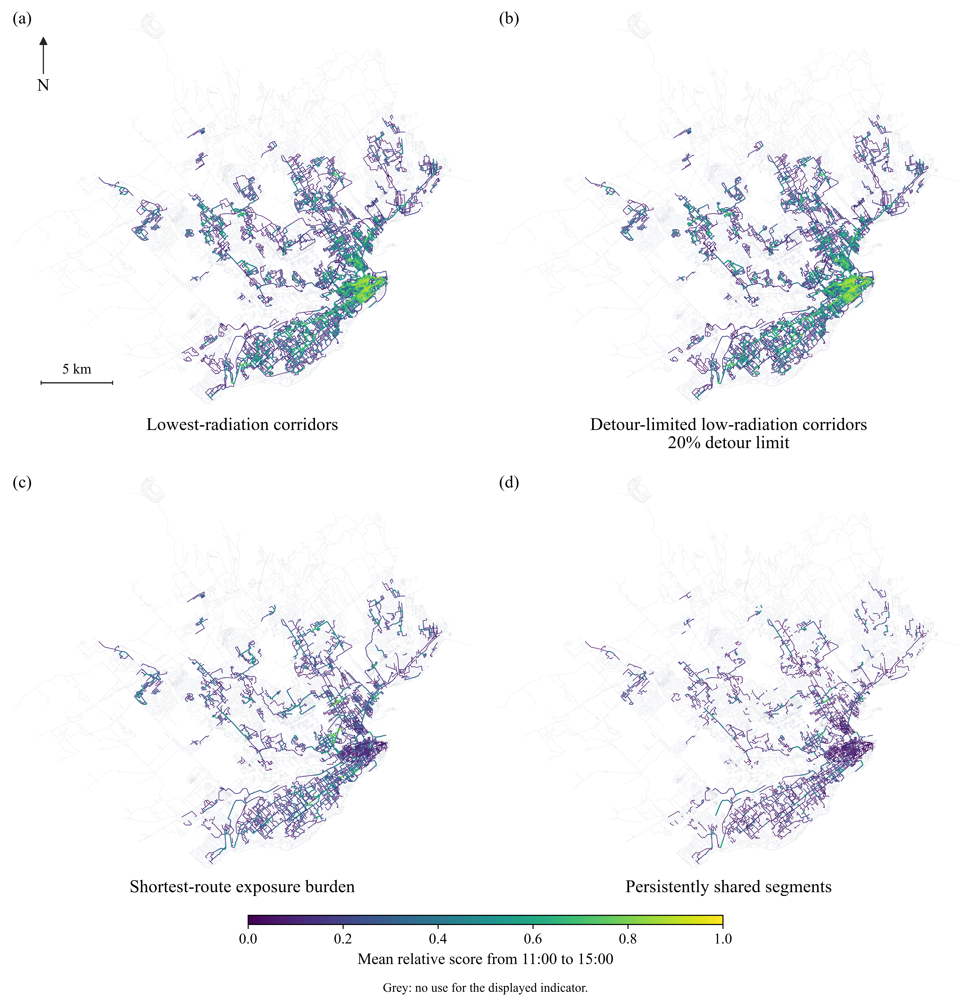

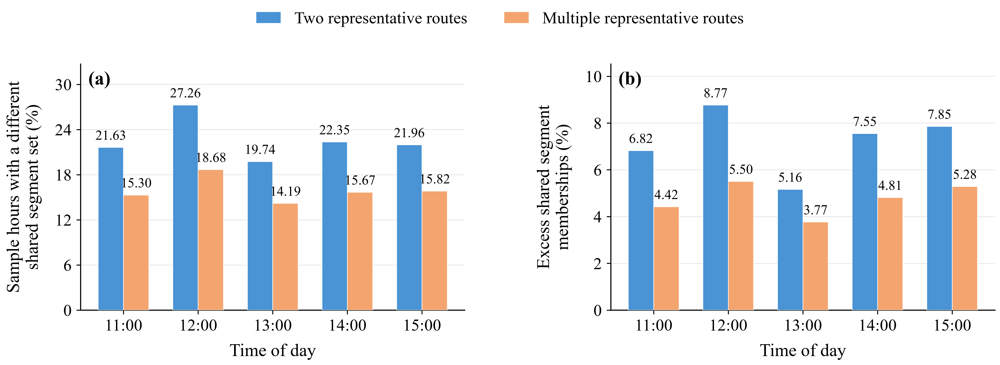

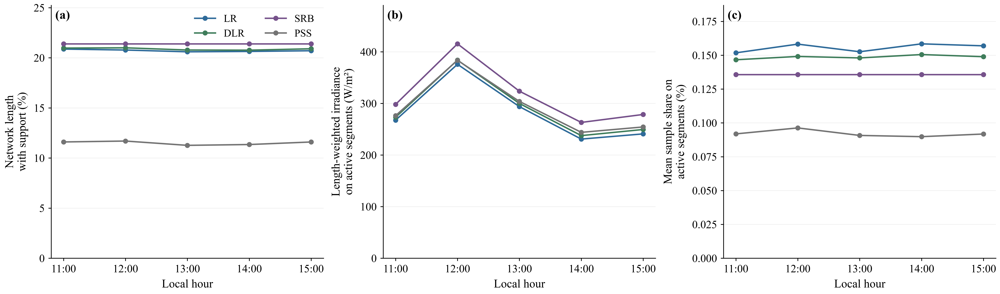

In [12]:
from IPython.display import display, Image

result_dir = Path(OUTPUT_DIR)
run_manifest = load_json(result_dir / "manifest.json")
decimals = STYLE["display_decimals"]

display(pd.read_csv(result_dir / "tables/manuscript_network_functions.csv").round(decimals))
display(pd.read_csv(result_dir / "tables/hourly_task_summary.csv").round(decimals))
comparison = pd.read_csv(result_dir / "tables/frontier_value_summary.csv")
display(comparison.loc[comparison.scope.eq("pooled"), [
    "method", "eligible_sample_hours", "changed_sample_hours", "changed_sample_hours_pct",
    "shared_sample_hour_segment_memberships", "excess_sample_hour_segment_memberships",
    "excess_membership_share_pct", "mean_excess_parent_length_m",
]].round(decimals))
for filename in run_manifest["preview_figures"]:
    display(Image(filename=str(result_dir / filename), width=1100))
